# plot_01. ERA5: model evaluation and observed change (figures)

Everything here is drawn from what notebooks calc_03a and calc_03b (part 1) and calc_03c (part 2) saved, so nothing slow runs. calc_03a saved each statistic's values as they are, every member's and ERA5's; where ERA5 falls among the members (its percentile, the verdicts and the field test) is worked out here from them, in *Where ERA5 Falls among the Members* and section 7. They explain each test and have a quick look at each step.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from plotting_modules import formatting
from plotting_modules.constants import SEASONS
from extant import era5_evaluation as ev, observed_change as oc
from extant.config import SATELLITE_YEAR_RANGE, VARIABLES
from extant.datatree import skip_empty, tree_to_dataset
from extant.logger import setup_logging
from extant.plots import antarctica, charts, era5_evaluation as evp, forced_response as fr, observed_change as ocp
from extant.plots import response_change as rcp

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

In [3]:
#(t): As in calc_03a to calc_03c: the variable (its name and units), and the grid point and its label
VARIABLE = VARIABLES['tas']
SAMPLE_LAT_LON = dict(lat=-82.5, lon=120.0)
POINT_LABEL = formatting.format_latlon(SAMPLE_LAT_LON)

#(t): The model of the one-model figures, and the region of part 2's
EXAMPLE_MODEL = 'CanESM5'
OBS_REGION = 'Antarctica (90–65°S)'

In [4]:
#(t): Where calc_03a to calc_03c saved their results: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SCRATCH_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt')

## Which Results

Run **one** of the next two sections: each sets the folder the results are opened from, the sample's or the full data's.

### Sample data

In [5]:
#(t): The sample's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

In [6]:
#(t): The full data's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

## Open the Results

First what calc_03a to calc_03c saved in `RESULTS_DIR`, then each result opened.

In [7]:
#(t): What calc_03a to calc_03c saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full'),
 ['anomaly_ranks.zarr',
  'demo_anomaly_ranks.zarr',
  'demo_detrended_ranks.zarr',
  'demo_plume.zarr',
  'demo_statistics.zarr',
  'demo_tests.zarr',
  'detections.zarr',
  'detrended_ranks.zarr',
  'era5_kurtosis.zarr',
  'era5_lower_tail.zarr',
  'era5_mean.zarr',
  'era5_point.zarr',
  'era5_regional.zarr',
  'era5_regional_trend.zarr',
  'era5_skewness.zarr',
  'era5_std.zarr',
  'era5_trend.zarr',
  'era5_upper_tail.zarr',
  'era5_width.zarr',
  'eval_map_table.zarr',
  'eval_table.zarr',
  'experiment_noise.zarr',
  'final_mean.zarr',
  'final_quantiles.zarr',
  'first_look.zarr',
  'forced.zarr',
  'hist_nat_final_quantiles.zarr',
  'histnat_point.zarr',
  'historical_kurtosis.zarr',
  'historical_lower_tail.zarr',
  'historical_mean.zarr',
  'historical_point.zarr',
  'historical_skewness.zarr',
  'historical_std.zarr',
  'historical_trend.zarr',
  'historical_upper_tail.zarr',
  'historical_width.zarr',
  'mean_

In [8]:
#(t): ERA5's 1979-2013 mean in every season, and each model's ensemble mean minus it
first_look_ds = xr.open_zarr(RESULTS_DIR / 'first_look.zarr').load()

In [9]:
#(t): At the point: each model's historical members, /<model>/historical
historical_point_tree = xr.open_datatree(RESULTS_DIR / 'historical_point.zarr', engine='zarr').load()

In [10]:
#(t): ... their hist-nat members, /<model>/hist-nat
histnat_point_tree = xr.open_datatree(RESULTS_DIR / 'histnat_point.zarr', engine='zarr').load()

In [11]:
#(t): ... and ERA5
era5_point_da = xr.open_zarr(RESULTS_DIR / 'era5_point.zarr')['tas'].load()

In [12]:
#(t): Every member's mean at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_mean_tree = xr.open_datatree(RESULTS_DIR / 'historical_mean.zarr', engine='zarr').load()
era5_mean_da = xr.open_zarr(RESULTS_DIR / 'era5_mean.zarr')[VARIABLE.name].load()

In [13]:
#(t): Every member's standard deviation (detrended) at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_std_tree = xr.open_datatree(RESULTS_DIR / 'historical_std.zarr', engine='zarr').load()
era5_std_da = xr.open_zarr(RESULTS_DIR / 'era5_std.zarr')[VARIABLE.name].load()

In [14]:
#(t): Every member's skewness (detrended) at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_skewness_tree = xr.open_datatree(RESULTS_DIR / 'historical_skewness.zarr', engine='zarr').load()
era5_skewness_da = xr.open_zarr(RESULTS_DIR / 'era5_skewness.zarr')[VARIABLE.name].load()

In [15]:
#(t): Every member's excess kurtosis (detrended) at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_kurtosis_tree = xr.open_datatree(RESULTS_DIR / 'historical_kurtosis.zarr', engine='zarr').load()
era5_kurtosis_da = xr.open_zarr(RESULTS_DIR / 'era5_kurtosis.zarr')[VARIABLE.name].load()

In [16]:
#(t): Every member's trend at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_trend_tree = xr.open_datatree(RESULTS_DIR / 'historical_trend.zarr', engine='zarr').load()
era5_trend_da = xr.open_zarr(RESULTS_DIR / 'era5_trend.zarr')[VARIABLE.name].load()

In [17]:
#(t): Every member's width (detrended) at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_width_tree = xr.open_datatree(RESULTS_DIR / 'historical_width.zarr', engine='zarr').load()
era5_width_da = xr.open_zarr(RESULTS_DIR / 'era5_width.zarr')[VARIABLE.name].load()

In [18]:
#(t): Every member's lower tail (detrended) at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_lower_tail_tree = xr.open_datatree(RESULTS_DIR / 'historical_lower_tail.zarr', engine='zarr').load()
era5_lower_tail_da = xr.open_zarr(RESULTS_DIR / 'era5_lower_tail.zarr')[VARIABLE.name].load()

In [19]:
#(t): Every member's upper tail (detrended) at every grid point (calc_03a), /<model>/historical on (member, season, lat, lon), and ERA5's
historical_upper_tail_tree = xr.open_datatree(RESULTS_DIR / 'historical_upper_tail.zarr', engine='zarr').load()
era5_upper_tail_da = xr.open_zarr(RESULTS_DIR / 'era5_upper_tail.zarr')[VARIABLE.name].load()

In [20]:
#(t): ... the rank histograms of the raw values
raw_ranks_tree = xr.open_datatree(RESULTS_DIR / 'raw_ranks.zarr', engine='zarr').load()

In [21]:
#(t): ... of the anomalies
anomaly_ranks_tree = xr.open_datatree(RESULTS_DIR / 'anomaly_ranks.zarr', engine='zarr').load()

In [22]:
#(t): ... and of the detrended anomalies
detrended_ranks_tree = xr.open_datatree(RESULTS_DIR / 'detrended_ranks.zarr', engine='zarr').load()

In [23]:
#(t): Every test's percentile and verdict, on (model, statistic, season)
eval_table_ds = xr.open_zarr(RESULTS_DIR / 'eval_table.zarr').load()

In [24]:
#(t): The rank test step by step: EXAMPLE_MODEL's anomalies in one season
rank_anatomy_ds = xr.open_zarr(RESULTS_DIR / 'rank_anatomy_data.zarr').load()

In [25]:
#(t): ... and the test
anatomy_result_ds = xr.open_zarr(RESULTS_DIR / 'rank_anatomy_test.zarr').load()

In [26]:
#(t): The toy ensembles: every member's and pseudo-ERA5's mean, trend, standard deviation and width
demo_statistics_ds = xr.open_zarr(RESULTS_DIR / 'demo_statistics.zarr').load()

In [27]:
#(t): ... the rank-histogram tests of the anomalies
demo_anomaly_ranks_ds = xr.open_zarr(RESULTS_DIR / 'demo_anomaly_ranks.zarr').load()

In [28]:
#(t): ... and of the detrended anomalies
demo_detrended_ranks_ds = xr.open_zarr(RESULTS_DIR / 'demo_detrended_ranks.zarr').load()

In [29]:
#(t): ... and the plumes
demo_plume_ds = xr.open_zarr(RESULTS_DIR / 'demo_plume.zarr').load()

In [30]:
#(t): The spatial evaluation (calc_03b)
spatial_table_ds = xr.open_zarr(RESULTS_DIR / 'spatial_table.zarr').load()

In [31]:
#(t): Part 2 (calc_03c's): ERA5 among each experiment in OBS_REGION, /<model>/<experiment>
region_tests_tree = xr.open_datatree(RESULTS_DIR / 'region_tests.zarr', engine='zarr').load()

In [32]:
#(t): ... the record curves in OBS_REGION
record_curves_ds = xr.open_zarr(RESULTS_DIR / 'record_curves.zarr').load()

In [33]:
#(t): ... and at the point
point_curves_ds = xr.open_zarr(RESULTS_DIR / 'point_record_curves.zarr').load()

In [34]:
#(t): ... the detection maps
detections_ds = xr.open_zarr(RESULTS_DIR / 'detections.zarr').load()

In [35]:
#(t): ... the scaling factors of ANT and NAT
scaling_ant_nat_ds = xr.open_zarr(RESULTS_DIR / 'scaling_ant_nat.zarr').load()

In [36]:
#(t): ... and of the single forcings
scaling_single_ds = xr.open_zarr(RESULTS_DIR / 'scaling_single_forcings.zarr').load()

## First Look

ERA5's 1979–2013 mean in every season, and each model's historical ensemble mean minus it: the mean-state bias, which only the tests of raw values see.

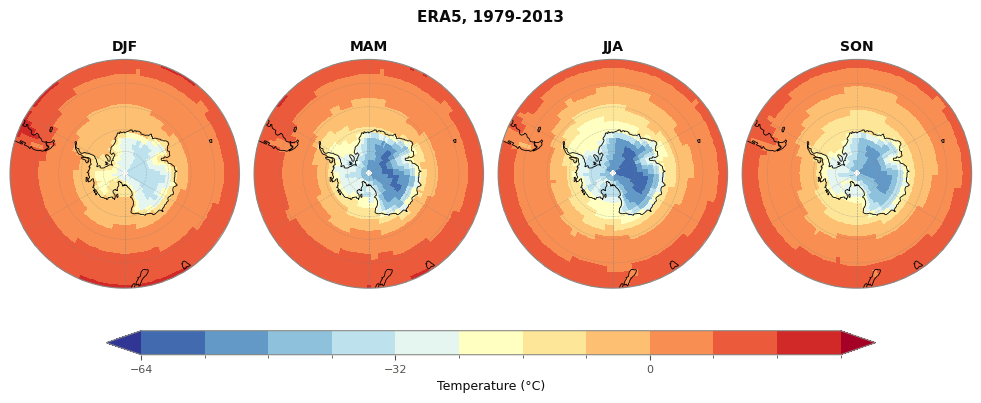

In [37]:
#(t): ERA5's mean temperature in every season (columns), 1979-2013, on its own range in about 14 round steps
#(t): (MaxNLocator), with every fourth labelled
era5_climatology_da = first_look_ds['era5_mean'].sel(season=SEASONS)
levels = MaxNLocator(14).tick_values(float(era5_climatology_da.min()), float(era5_climatology_da.max()))
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=1, n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=1, n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(era5_climatology_da, None, 'season', axes=axes, cax=cax, levels=levels,
                                  cmap='RdYlBu_r', ticks=levels[::4], label=f'Temperature ({VARIABLE.units})')
antarctica.label_columns(axes, SEASONS)
fig.suptitle('ERA5, 1979-2013');

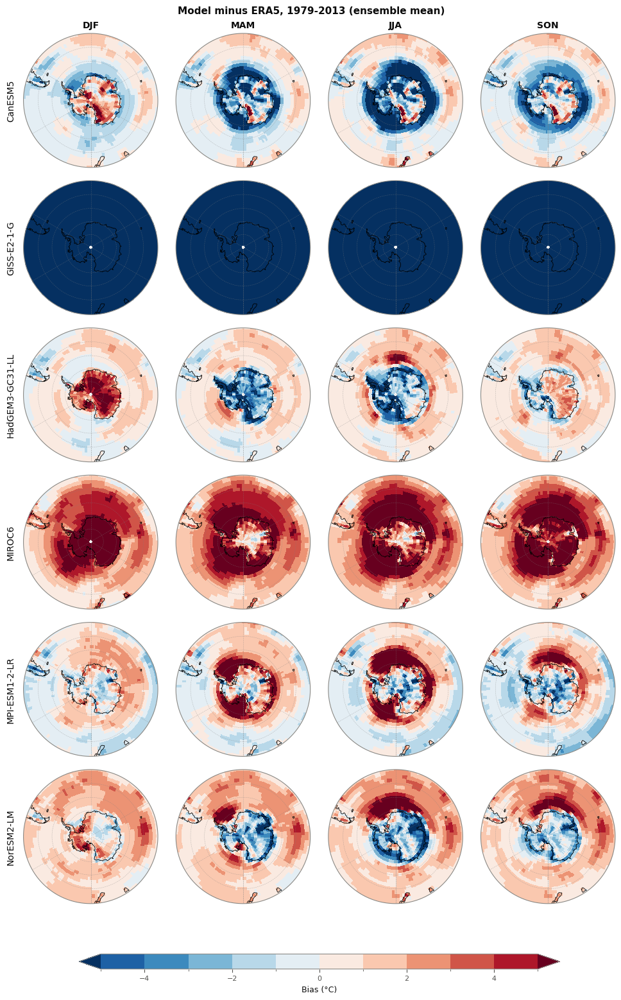

In [38]:
#(t): Each model's (rows) ensemble-mean bias against ERA5, every season (columns)
model_bias_da = first_look_ds['model_bias'].sel(season=SEASONS)
models = model_bias_da['model'].values
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(model_bias_da, 'model', 'season', axes=axes, cax=cax,
                                  levels=np.linspace(-5, 5, 11), cmap='RdBu_r', label=f'Bias ({VARIABLE.units})')
antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
fig.suptitle('Model minus ERA5, 1979-2013 (ensemble mean)');

## Where ERA5 Falls among the Members

Notebook calc_03a saved each statistic's values as they are: every member's and ERA5's. `ev.locate` places ERA5's value among the members': ERA5's **percentile** among them (ties count half), the two-sided **p-value** (twice the smaller tail, ERA5 counted as one more member: 2 × (members at or beyond ERA5 on that side + 1) / (N + 1)), the **verdict** (−1 ERA5 below the members, +1 above, 0 not flagged; flagged when p < 0.1, i.e. ERA5 outside the members' 5–95%), whether the model has enough members to flag anything at all (**testable**: N ≥ 20), and the members' 5%, 50% and 95% for the figures. First step by step, then for every model, statistic and season at the point; section 7 does the same at every grid point.

**How `ev.locate` places ERA5 among the members**, step by step on EXAMPLE_MODEL's DJF means at the point. Every test in this notebook and in calc_03b's table ends with it, so these steps give every percentile, p-value and verdict.

In [39]:
#(t): EXAMPLE_MODEL's members' DJF means at the point, and ERA5's
locate_members_da = historical_mean_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].sel(SAMPLE_LAT_LON).sel(season='DJF')
locate_era5_da = era5_mean_da.sel(SAMPLE_LAT_LON).sel(season='DJF')

In [40]:
#(t): How many members there are, how many are less than ERA5, and how many equal it
n_locate_members = int(locate_members_da.notnull().sum())
n_less = int((locate_members_da < locate_era5_da).sum())
n_equal = int((locate_members_da == locate_era5_da).sum())

In [41]:
#(t): ERA5's percentile: the share of the members less than ERA5, a member equal to it counting half
# Example: 4 members [1.0, 2.0, 3.0, 5.0] and ERA5 = 3.0. Two members are less than ERA5 and one equals it.
# The one equal to it counts half, so ERA5 is greater than 2.5 of the 4 members, and its percentile is 100 * 2.5 / 4 = 62.5.
# A perfect model puts ERA5 at any percentile from 0 to 100 equally often.
locate_percentile = 100 * (n_less + 0.5 * n_equal) / n_locate_members

In [42]:
#(t): The two tails: with ERA5 as one more member, the share of the N + 1 values at or less than ERA5, and at or greater
# Example: 20 members, all of them less than ERA5. With ERA5 as one more member there are 21 values.
# All 21 are at or less than ERA5, so the lower tail is (20 + 0 + 1) / 21 = 1.
# Only ERA5 itself is at or greater than ERA5, so the upper tail is (20 - 20 + 1) / 21 = 0.048.
# The + 1s are ERA5 counted as one more member, so neither tail can be 0.
lower_tail = (n_less + n_equal + 1) / (n_locate_members + 1)
upper_tail = (n_locate_members - n_less + 1) / (n_locate_members + 1)

In [43]:
#(t): The two-sided p-value: twice the smaller tail, at most 1
# In the example, twice 0.048 is 0.095.
locate_pvalue = min(2 * min(lower_tail, upper_tail), 1)

In [44]:
#(t): The verdict: flagged when the p-value is less than ALPHA (0.1), -1 if ERA5 is less than the members' middle and +1 if greater
# In the example, 0.095 is less than 0.1 and ERA5's percentile is 100, so the verdict is +1.
# With 19 members, even ERA5 greater than all of them gives 2 / 20 = 0.1, which is not less than 0.1, so nothing can ever
# be flagged: testable is False, and a verdict of 0 then means "untestable", not "consistent".
locate_verdict = int(np.sign(locate_percentile - 50)) if locate_pvalue < ev.ALPHA else 0
locate_testable = 2 / (n_locate_members + 1) < ev.ALPHA

In [45]:
#(t): Check: the steps against ev.locate
locate_check_ds = ev.locate(locate_members_da, locate_era5_da)
pd.DataFrame({'step by step': [locate_percentile, locate_pvalue, locate_verdict, locate_testable],
              'ev.locate': [float(locate_check_ds['percentile']), float(locate_check_ds['pvalue']),
                            int(locate_check_ds['verdict']), bool(locate_check_ds['testable'])]},
             index=['percentile', 'pvalue', 'verdict', 'testable'])

,step by step,ev.locate
percentile,0.0,0.0
pvalue,0.030303,0.030303
verdict,-1,-1
testable,True,True


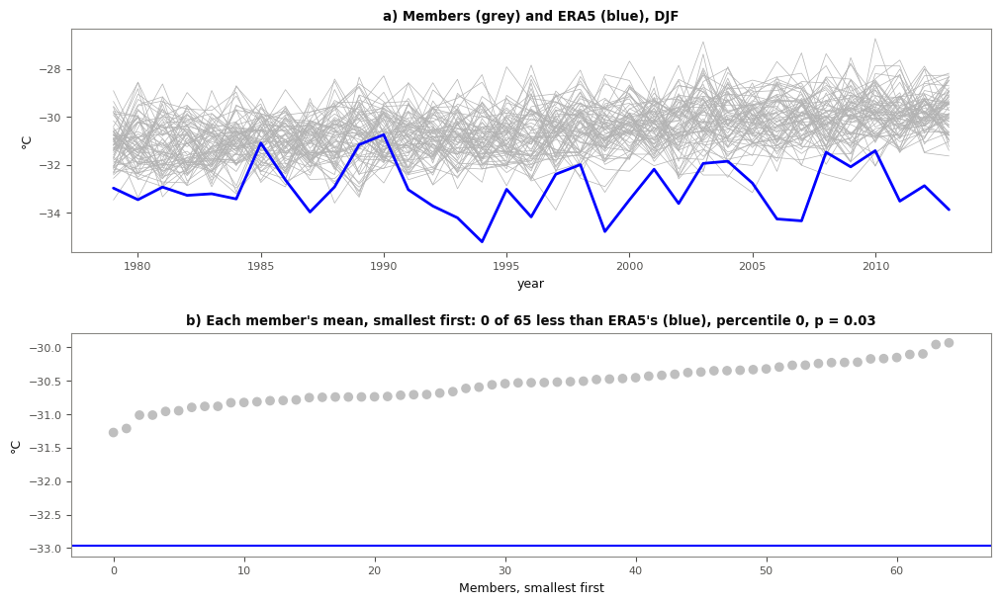

In [46]:
#(t): ev.locate step by step on EXAMPLE_MODEL's DJF means: a) the members (grey) and ERA5 (blue) through the years, the
#(t): series the means are of; b) each member's mean, smallest first, dark where less than ERA5's (blue)
sorted_member_means_arr = np.sort(locate_members_da.values)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
historical_point_tree[EXAMPLE_MODEL]['historical'][VARIABLE.name].sel(season='DJF').plot.line(ax=ax1, x='year', hue='member',
                                                                                      add_legend=False, color='0.7',
                                                                                      lw=0.5)
era5_point_da.sel(season='DJF').plot(ax=ax1, color='blue', linewidth=2)
ax1.set(title='a) Members (grey) and ERA5 (blue), DJF', ylabel=VARIABLE.units)
ax2.scatter(np.arange(n_locate_members), sorted_member_means_arr,
            color=np.where(sorted_member_means_arr < float(locate_era5_da), '0.25', '0.75').tolist())
ax2.axhline(float(locate_era5_da), color='blue')
ax2.set(title=f"b) Each member's mean, smallest first: {n_less} of {n_locate_members} less than ERA5's (blue), "
              f"percentile {locate_percentile:.0f}, p = {locate_pvalue:.2f}",
        xlabel='Members, smallest first', ylabel=VARIABLE.units);

### Every model at the point

Each statistic at `SAMPLE_LAT_LON`: ERA5's value among each model's members' (`ev.locate`, as above), then the moment test's four and the other statistics' four along a `statistic` dim, for sections 2, 4 and 6.

In [47]:
#(t): The mean at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
mean_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_mean_da.sel(SAMPLE_LAT_LON))
    for node in historical_mean_tree.leaves
})

In [48]:
#(t): The standard deviation (detrended) at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
std_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_std_da.sel(SAMPLE_LAT_LON))
    for node in historical_std_tree.leaves
})

In [49]:
#(t): The skewness (detrended) at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
skewness_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_skewness_da.sel(SAMPLE_LAT_LON))
    for node in historical_skewness_tree.leaves
})

In [50]:
#(t): The excess kurtosis (detrended) at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
kurtosis_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_kurtosis_da.sel(SAMPLE_LAT_LON))
    for node in historical_kurtosis_tree.leaves
})

In [51]:
#(t): The moment test: each model's four along a statistic dim
moment_test_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), std_test_tree[node.path].to_dataset(),
                          skewness_test_tree[node.path].to_dataset(), kurtosis_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['mean', 'std', 'skewness', 'kurtosis']))
    for node in mean_test_tree.leaves
})

In [52]:
#(t): With the values each moment was worked out on, for the figures' labels
moment_test_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset().assign_coords(treatment=('statistic', ['raw', 'detrended', 'detrended', 'detrended']))
    for node in moment_test_tree.leaves
})
moment_test_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:     (statistic: 4, season: 4, member: 65)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -30.53 ... -0.4231
│               lower       (statistic, season) float64 128B -31.0 -58.55 ... -0.9818 -1.007
│               median      (statistic, season) float64 128B -30.53 -58.08 ... -0.3695
│               upper       (statistic, season) float64 128B -30.12 -57.55 ... 1.034 0.6424
│               percentile  (statistic, season) float64 128B 0.0 100.0 100.0 ... 70.77 30.77
│               pvalue      (statistic, season) float64 128B 0.0303 0.0303 ... 0.6061 0.6364
│               verdict     (statistic, season) float64 128B -1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:     (statistic: 4, season: 4, member: 63)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -273.1 -273.1 ... nan
│               lower       (statistic, season) float64 128B -273.1 -273.1 ... -1.125
│               median      (statistic, season) float64 128B -33.27 -60.47 ... -0.235
│               upper       (statistic, season) float64 128B -32.26 -59.65 ... 1.771 1.849
│               percentile  (statistic, season) float64 128B 63.49 100.0 ... 53.33 37.78
│               pvalue      (statistic, season) float64 128B 0.75 0.03125 ... 0.9565 0.7826
│               verdict     (statistic, season) float64 128B 0.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:     (statistic: 4, season: 4, member: 55)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 7kB -28.02 -56.41 ... 0.1943
│               lower       (statistic, season) float64 128B -28.02 -56.54 ... -0.9203
│               median      (statistic, season) float64 128B -27.71 -56.09 ... -0.3381
│               upper       (statistic, season) float64 128B -27.32 -55.54 ... 0.9406 0.96
│               percentile  (statistic, season) float64 128B 0.0 100.0 100.0 ... 61.

In [53]:
#(t): The trend at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
trend_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_trend_da.sel(SAMPLE_LAT_LON))
    for node in historical_trend_tree.leaves
})

In [54]:
#(t): The width (detrended) at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
width_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_width_da.sel(SAMPLE_LAT_LON))
    for node in historical_width_tree.leaves
})

In [55]:
#(t): The lower tail (detrended) at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
lower_tail_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_lower_tail_da.sel(SAMPLE_LAT_LON))
    for node in historical_lower_tail_tree.leaves
})

In [56]:
#(t): The upper tail (detrended) at the point: where ERA5's falls among each model's members, /<model>/historical, on (member, season)
upper_tail_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name].sel(SAMPLE_LAT_LON), era5_upper_tail_da.sel(SAMPLE_LAT_LON))
    for node in historical_upper_tail_tree.leaves
})

In [57]:
#(t): The other statistics: each model's four along a statistic dim, with the values each was worked out on
statistic_test_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), width_test_tree[node.path].to_dataset(),
                          lower_tail_test_tree[node.path].to_dataset(), upper_tail_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['trend', 'width', 'lower_tail', 'upper_tail']))
    for node in trend_test_tree.leaves
})
statistic_test_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset().assign_coords(treatment=('statistic', ['raw', 'detrended', 'detrended', 'detrended']))
    for node in statistic_test_tree.leaves
})
statistic_test_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:     (statistic: 4, season: 4, member: 65)
│           Coordinates:
│               lat         float64 8B -82.5
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * statistic   (statistic) <U10 160B 'trend' 'width' 'lower_tail' 'upper_tail'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B 0.01296 0.1282 ... 2.271 1.786
│               members     (statistic, member, season) float64 8kB -0.04846 ... 1.522
│               lower       (statistic, season) float64 128B 0.1112 -0.1618 ... 1.373 1.304
│               median      (statistic, season) float64 128B 0.4332 0.3684 ... 2.072 1.904
│               upper       (statistic, season) float64 128B 0.6944 0.7645 ... 2.794 2.799
│               percentile  (statistic, season) float64 128B 1.538 21.54 0.0 ... 66.15 40.0
│               pvalue      (statistic, season) float64 128B 0.06061 0.4545 ... 0.697 0.8182
│               verdict     (statistic, season) float64 128B -1.0 0.0 -1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /MPI-ESM1-2-LR
│   └── Group: /MPI-ESM1-2-LR/historical
│           Dimensions:     (statistic: 4, season: 4, member: 51)
│           Coordinates:
│               lat         float64 8B -82.5
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member      (member) object 408B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * statistic   (statistic) <U10 160B 'trend' 'width' 'lower_tail' 'upper_tail'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B 0.01296 0.1282 ... 2.271 1.786
│               members     (statistic, member, season) float64 7kB 0.3169 0.9491 ... 3.671
│               lower       (statistic, season) float64 128B -0.04961 -0.2558 ... 1.73 1.65
│               median      (statistic, season) float64 128B 0.1997 0.2835 ... 2.572 2.541
│               upper       (statistic, season) float64 128B 0.5053 0.8882 ... 3.358 3.527
│               percentile  (statistic, season) float64 128B 15.69 35.29 ... 23.53 7.843
│               pvalue      (statistic, season) float64 128B 0.3462 0.7308 ... 0.5 0.1923
│               verdict     (statistic, season) float64 128B 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:     (statistic: 4, season: 4, member: 63)
│           Coordinates:
│               lat         float64 8B -82.5
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member      (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * statistic   (statistic) <U10 160B 'trend' 'width' 'lower_tail' 'upper_tail'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B 0.01296 0.1282 ... 2.271 1.786
│               members     (statistic, member, season) float64 8kB 0.0 0.0 0.0 ... 0.0 0.0
│               lower       (statistic, season) float64 128B -0.09403 -0.1822 ... 0.0 0.0
│               median      (statistic, season) float64 128B 0.04392 0.0008862 ... 1.789
│               upper       (statistic, season) float64 128B 0.5523 0.5188 ... 3.25 2.823
│               percentile  (stati

## 1. How the Tests Work: Toy Ensembles

Before trusting the tests on real data, here they are on synthetic ensembles where we *know* what is wrong. `ev.simulate_ensemble` (notebooks calc_03a and calc_03b) makes 50 members and a pseudo-ERA5, 1979–2013, four seasons, each series `trend × decades + noise × N(0, 1)`. Pseudo-ERA5 always has a trend of 0.3 per decade and noise 1; each scenario (`ev.SCENARIOS`) changes one thing about the model:

| Scenario | The model | What the tests should say |
|---|---|---|
| Consistent | identical to ERA5 | nothing flagged, apart from ~10% by chance |
| Too little noise | noise 0.6x | ERA5 often outside the plume; U-shaped histograms; std flagged high |
| Too much noise | noise 1.6x | ERA5 never leaves the plume; dome-shaped histograms; std flagged low |
| Signal too strong | trend 0.9/decade | U shape for anomalies but **flat once detrended**; trend and rank trend flagged |
| Mean-state bias | 2° too warm | raw plume offset; only the mean flagged; every anomaly test passes |

Columns: the raw time series with the plume; the rank histograms of anomalies and of detrended anomalies (bars: pseudo-ERA5; grey bars: the range a perfect model gives); ERA5's percentile for each statistic (✓ inside the grey 5–95% band, ✗ outside).

In [58]:
#(t): Where pseudo-ERA5 falls among each toy ensemble's members (ev.locate), every statistic, scenario and season
demo_tests_ds = ev.locate(demo_statistics_ds['members'], demo_statistics_ds['era5'])
demo_tests_ds

<xarray.Dataset> Size: 38kB
Dimensions:     (statistic: 4, scenario: 5, season: 4, member: 50)
Coordinates:
  * season      (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * scenario    (scenario) object 40B 'Consistent' ... 'Mean-state bias'
  * statistic   (statistic) object 32B 'mean' 'trend' 'std' 'width'
  * member      (member) int64 400B 0 1 2 3 4 5 6 7 ... 42 43 44 45 46 47 48 49
Data variables:
    era5        (statistic, scenario, season) float64 640B 0.3109 ... 3.26
    members     (statistic, scenario, member, season) float64 32kB 0.4471 ......
    lower       (statistic, scenario, season) float64 640B 0.2515 ... 2.293
    median      (statistic, scenario, season) float64 640B 0.5175 ... 3.041
    upper       (statistic, scenario, season) float64 640B 0.7684 ... 3.719
    percentile  (statistic, scenario, season) float64 640B 14.0 88.0 ... 68.0
    pvalue      (statistic, scenario, season) float64 640B 0.3137 ... 0.6667
    verdict     (statistic, scenario, season) float64 640B 0.0 0.0 ... 0.0 0.0
    testable    (statistic, scenario, season) float64 640B 1.0 1.0 ... 1.0 1.0

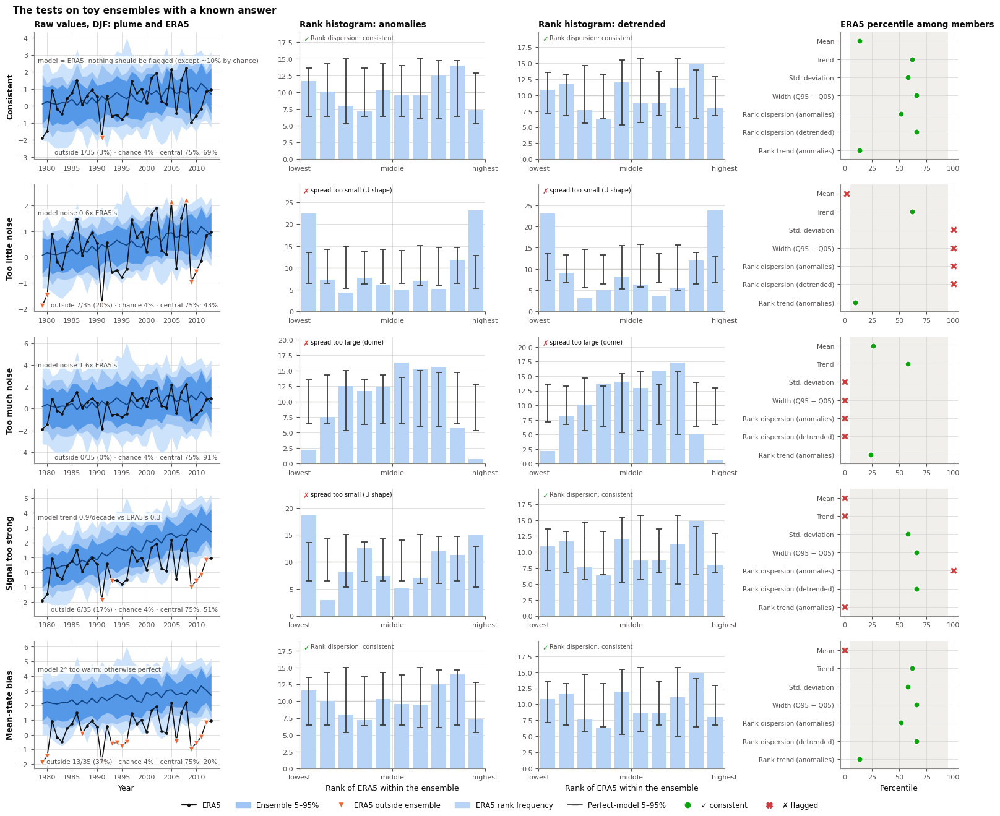

In [59]:
#(t): The tests on toy ensembles with a known answer, one scenario per row: the raw values in DJF with the plume (the
#(t): toy seasons are alike, so one is shown), the
#(t): rank histograms of anomalies and of detrended anomalies, and ERA5's percentile for each statistic (green: inside
#(t): the members' central range; red cross: flagged). The ladder is a block of its own, for room for its labels
scenarios = list(demo_plume_ds['scenario'].values)
fig = plt.figure(figsize=(15.5, 2.3 * len(scenarios) + 1.6), layout='constrained')
#(c): The three columns of panels, and the ladder beside them
grid = fig.add_gridspec(1, 2, width_ratios=[3.3, 1])
axes = grid[0].subgridspec(len(scenarios), 3).subplots(squeeze=False)
ladder_axes = grid[1].subgridspec(len(scenarios), 1).subplots(squeeze=False)
for i, scenario in enumerate(scenarios):
    evp.plot_plume(demo_plume_ds.sel(scenario=scenario, season='DJF'), ax=axes[i, 0])
    axes[i, 0].text(0.02, 0.8, ev.SCENARIO_DESCRIPTIONS.get(scenario, ''), transform=axes[i, 0].transAxes, fontsize=7.5,
                    color=evp.INK_2, va='top', zorder=20,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1))
    axes[i, 0].set_ylabel(scenario, fontweight='bold')
    evp.plot_grouped_rank_histogram(demo_anomaly_ranks_ds.sel(scenario=scenario), ax=axes[i, 1],
                                    statistics=('dispersion',))
    evp.plot_grouped_rank_histogram(demo_detrended_ranks_ds.sel(scenario=scenario), ax=axes[i, 2],
                                    statistics=('dispersion',))
    evp.plot_percentile_ladder(demo_tests_ds.sel(scenario=scenario, season='DJF'),
                               demo_anomaly_ranks_ds.sel(scenario=scenario),
                               demo_detrended_ranks_ds.sel(scenario=scenario), ax=ladder_axes[i, 0])

axes[0, 0].set_title('Raw values, DJF: plume and ERA5', loc='left')
axes[0, 1].set_title('Rank histogram: anomalies', loc='left')
axes[0, 2].set_title('Rank histogram: detrended', loc='left')
ladder_axes[0, 0].set_title('ERA5 percentile among members', loc='left')
axes[-1, 0].set_xlabel('Year')
for ax in axes[-1, 1:]:
    ax.set_xlabel('Rank of ERA5 within the ensemble')
ladder_axes[-1, 0].set_xlabel('Percentile')
fig.legend(handles=evp.scenario_legend_handles(), loc='outside lower center', ncols=7, frameon=False)
fig.suptitle('The tests on toy ensembles with a known answer', x=0.01, ha='left');

**Reading the figure**
- **Signal vs noise.** Compare the two rank-histogram columns. A noise problem (rows 2–3) shows in both. A signal problem (row 4) shows only for anomalies: a trend mismatch pushes ERA5 out of the ensemble at both ends of the record, which looks like a U, and detrending removes it.
- **Raw values vs anomalies.** A mean-state bias (row 5) puts ERA5 outside the raw plume much of the time, but once each series is measured from its own mean, every test passes. This is the "raw values don't fit but the anomalies do" case.
- **Too little noise can also flag the mean.** A too-narrow ensemble underestimates how far a 35-year mean can wander. So read the noise tests first.

**Calibration**

Over 200 random toy worlds (40 members), a perfect model is flagged 6–12% of the time for every statistic (nominally 10%). Each fault is caught by its intended test almost every time:

| | noise too small | noise too large | signal too strong | mean bias |
|---|---|---|---|---|
| std (detrended) | 99% | 97% | 10% | 10% |
| width, Q95 − Q05 | 96% | 92% | – | – |
| cold / warm tail | 76% / 77% | 57% / 59% | – | – |
| rank dispersion (anomalies) | 100% | 100% | 68% | 6% |
| rank dispersion (detrended) | 100% | 100% | 8% | 8% |
| trend | 35% | 2% | 96% | 12% |
| rank trend | 21% | 4% | 100% | 9% |
| mean | 30% | 2% | 100% | 100% |

The tail tests are the weakest: with ~35 values per season, each tail rests on about two of them. A ✓ for a tail therefore means "no evidence of a problem", which is weaker than a ✓ for the width or std.

## 2. Distributions: Raw Values and Anomalies

For each season: each member's KDE (thin), the pooled ensemble (thick blue) and ERA5's (black), with ERA5's values as a rug; the ✓/✗ is the moment test of the mean (raw values) or of the standard deviation (anomalies). The Q–Q panel: the members' quantiles against ERA5's; on the 1:1 line the distributions match. ERA5 and every member share one kernel bandwidth, so differences come from the data rather than the smoothing.

In [60]:
#(t): EXAMPLE_MODEL's members and ERA5 at the point
eval_members_da = historical_point_tree[EXAMPLE_MODEL]['historical']['tas']
eval_era5_da = era5_point_da
eval_era5_da

<xarray.DataArray 'tas' (year: 35, season: 4)> Size: 560B
-32.97 -55.57 -51.88 -45.79 -33.46 -53.79 ... -46.57 -33.87 -50.94 -51.86 -43.27
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
    lon      float64 8B 120.0
    lat      float64 8B -82.5

In [61]:
#(t): Their KDEs and quantiles, for the figure (ev.distribution_summary): raw values, anomalies, detrended
eval_distributions = ev.distribution_summary(eval_members_da, eval_era5_da, ('raw', 'anomaly', 'detrended'))
eval_distributions['anomaly']

<xarray.Dataset> Size: 1MB
Dimensions:           (season: 4, year: 35, x: 600, member: 65, quantile: 19)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
    lon               float64 8B 120.0
    lat               float64 8B -82.5
  * x                 (x) float64 5kB -8.516 -8.487 -8.458 ... 8.76 8.789 8.818
  * member            (member) object 520B 'r10i1p1f1' ... 'r9i1p2f1'
  * quantile          (quantile) float64 152B 0.05 0.1 0.15 ... 0.85 0.9 0.95
Data variables:
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    member_kde        (x, member, season) float64 1MB 3.013e-37 ... 1.269e-22
    ensemble_kde      (x, season) float64 19kB 1.645e-26 7.982e-08 ... 1.997e-14
    obs_kde           (x, season) float64 19kB 1.169e-34 1.706e-10 ... 5.094e-20
    member_quantiles  (quantile, member, season) float64 40kB -1.211 ... 1.625
    obs_quantiles     (quantile, season) float64 608B -1.5 -2.214 ... 1.741
    bandwidth         (season) float64 32B 0.5148 0.7834 0.707 0.6275
Attributes: (1)

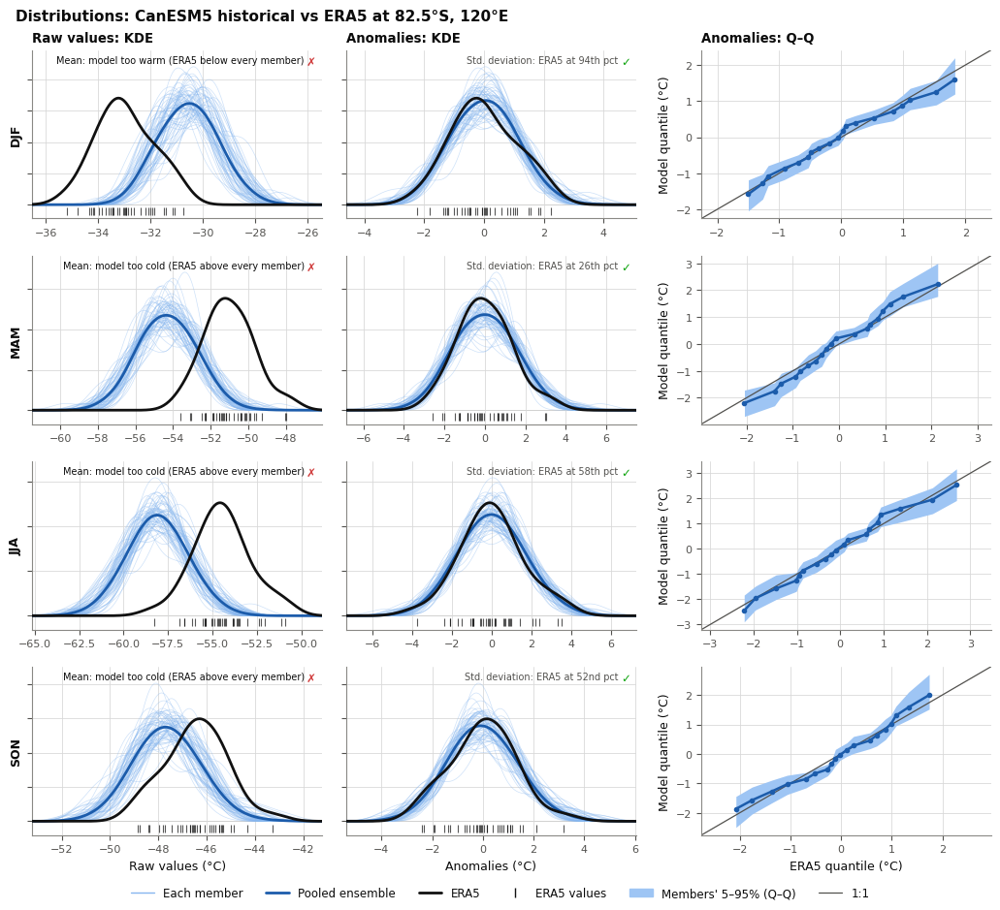

In [62]:
#(t): One model, every season (rows): the raw values' KDEs, the anomalies' KDEs and the anomalies' Q-Q plot, each KDE
#(t): panel with its moment test (the mean on raw values, the standard deviation on anomalies: evp.KDE_STATISTIC)
model_moments_ds = moment_test_tree[EXAMPLE_MODEL]['historical'].to_dataset()
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=3, n_legends=1, panel_height=1.5),
                 layout='constrained')
axes = fig.add_gridspec(len(SEASONS), 3).subplots(squeeze=False)
for i, season in enumerate(SEASONS):
    evp.plot_kde(eval_distributions['raw'].sel(season=season), ax=axes[i, 0])
    evp.plot_kde(eval_distributions['anomaly'].sel(season=season), ax=axes[i, 1])
    evp.plot_qq(eval_distributions['anomaly'].sel(season=season), ax=axes[i, 2])
    for ax, treatment in zip(axes[i, :2], ['raw', 'anomaly']):
        ok, message = evp.verdict(model_moments_ds.sel(season=season), evp.KDE_STATISTIC[treatment])
        evp.status_line(ax, 0.98, 0.97, ok, message, ha='right', fontsize=7)
        ax.tick_params(axis='y', labelleft=False)
    axes[i, 0].set_ylabel(season, fontweight='bold')
    axes[i, 2].set_ylabel(f'Model quantile ({VARIABLE.units})')

axes[0, 0].set_title(f"{ev.TREATMENTS['raw']}: KDE", loc='left')
axes[0, 1].set_title(f"{ev.TREATMENTS['anomaly']}: KDE", loc='left')
axes[0, 2].set_title(f"{ev.TREATMENTS['anomaly']}: Q–Q", loc='left')
axes[-1, 0].set_xlabel(f"{ev.TREATMENTS['raw']} ({VARIABLE.units})")
axes[-1, 1].set_xlabel(f"{ev.TREATMENTS['anomaly']} ({VARIABLE.units})")
axes[-1, 2].set_xlabel(f'ERA5 quantile ({VARIABLE.units})')
fig.legend(handles=evp.distribution_legend_handles(), loc='outside lower center', ncols=6, frameon=False)
fig.suptitle(f'Distributions: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

In [63]:
#(t): Every model's (raw values and anomalies), by model
all_distributions = {node.parent.name: ev.distribution_summary(node['tas'], era5_point_da, ('raw', 'anomaly'))
                     for node in historical_point_tree.leaves}

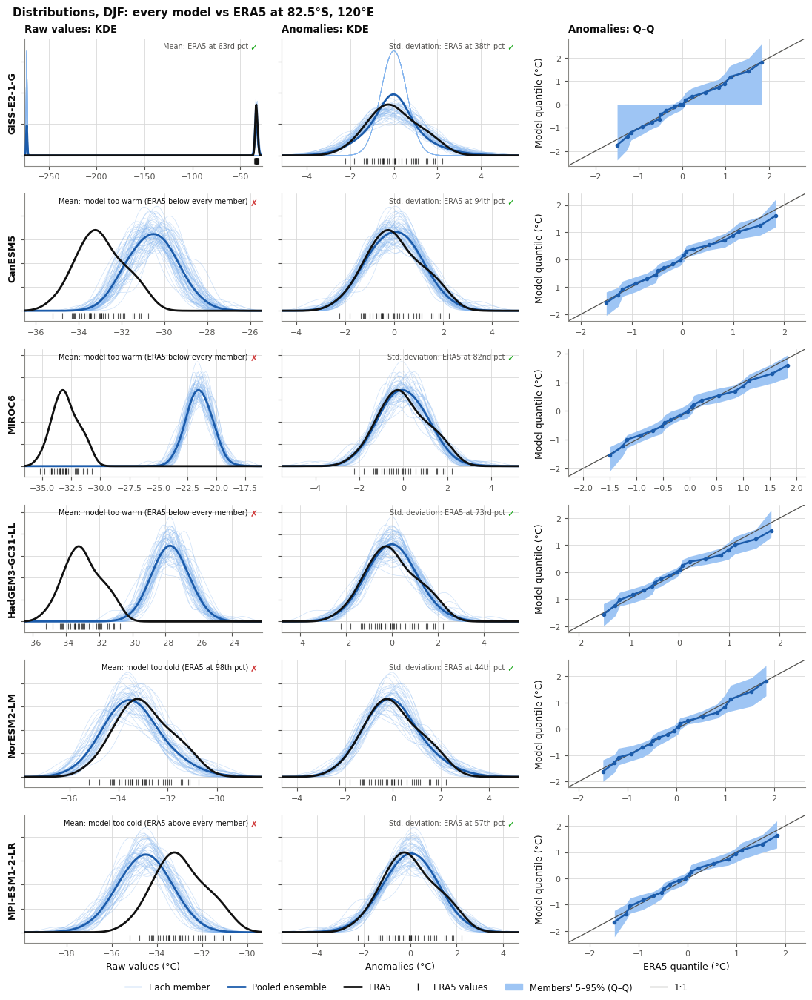

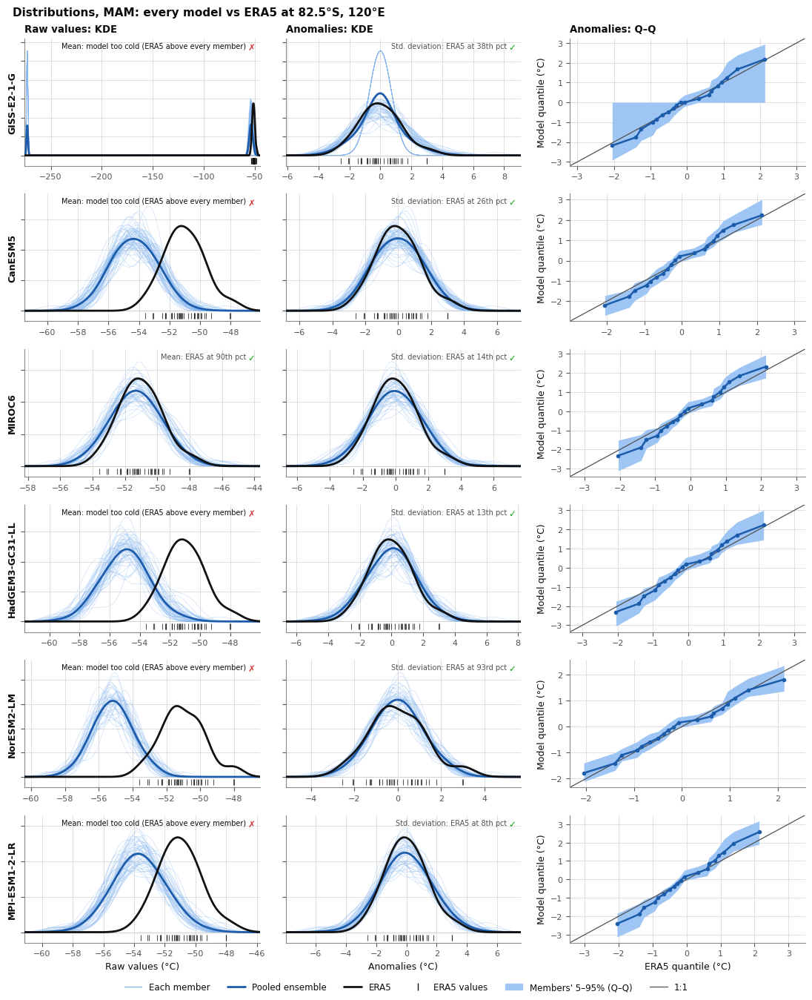

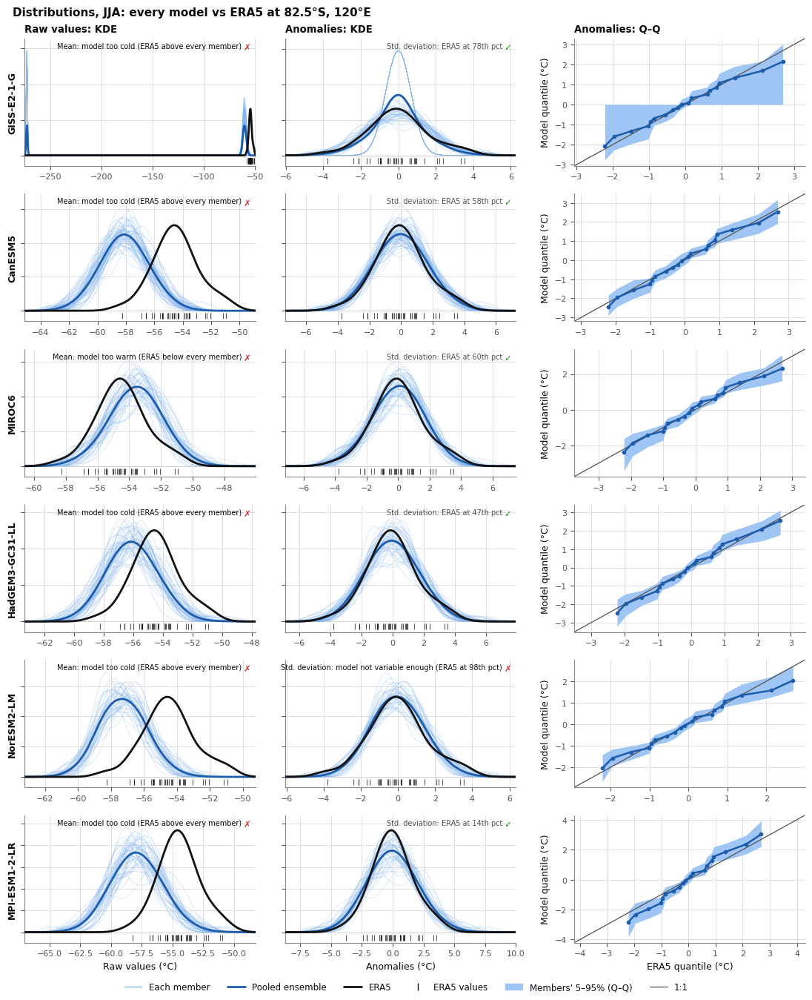

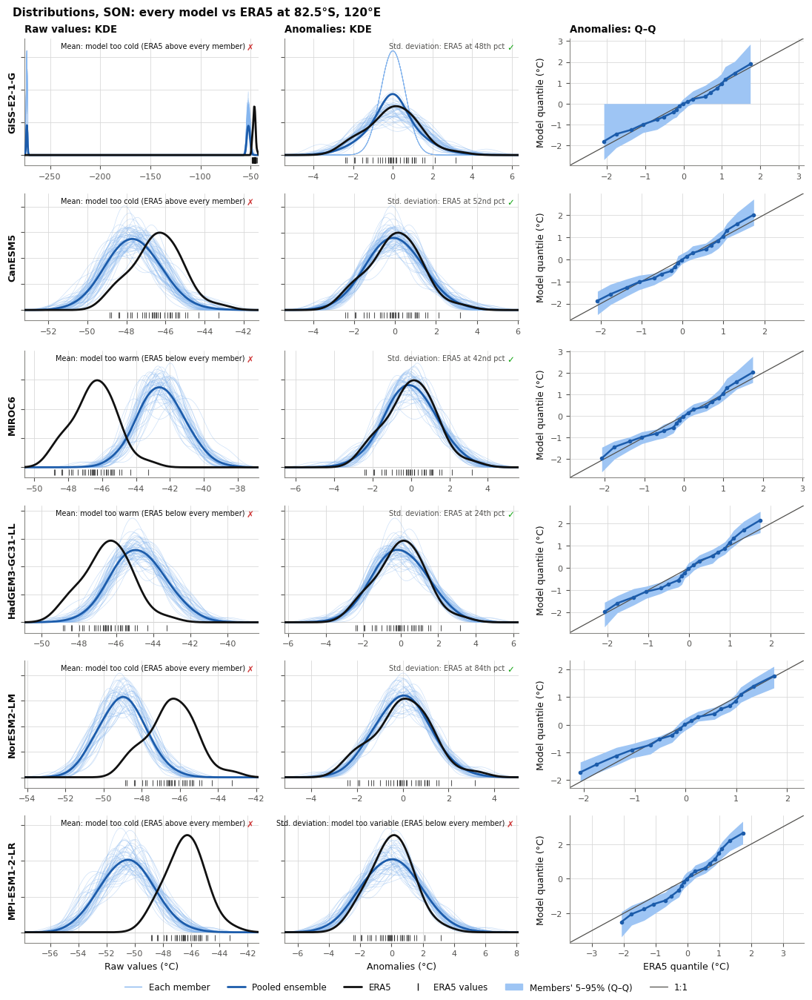

In [64]:
#(t): Every model (rows): the same three panels, one figure per season
distribution_models = list(all_distributions)
for season in SEASONS:
    fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(distribution_models), n_cols=3, n_legends=1,
                                                      panel_height=1.5, left_margin=1.4), layout='constrained')
    axes = fig.add_gridspec(len(distribution_models), 3).subplots(squeeze=False)
    for i, model in enumerate(distribution_models):
        evp.plot_kde(all_distributions[model]['raw'].sel(season=season), ax=axes[i, 0])
        evp.plot_kde(all_distributions[model]['anomaly'].sel(season=season), ax=axes[i, 1])
        evp.plot_qq(all_distributions[model]['anomaly'].sel(season=season), ax=axes[i, 2])
        row_moments_ds = moment_test_tree[model]['historical'].to_dataset().sel(season=season)
        for ax, treatment in zip(axes[i, :2], ['raw', 'anomaly']):
            ok, message = evp.verdict(row_moments_ds, evp.KDE_STATISTIC[treatment])
            evp.status_line(ax, 0.98, 0.97, ok, message, ha='right', fontsize=7)
            ax.tick_params(axis='y', labelleft=False)
        axes[i, 0].set_ylabel(model, fontweight='bold')
        axes[i, 2].set_ylabel(f'Model quantile ({VARIABLE.units})')

    axes[0, 0].set_title(f"{ev.TREATMENTS['raw']}: KDE", loc='left')
    axes[0, 1].set_title(f"{ev.TREATMENTS['anomaly']}: KDE", loc='left')
    axes[0, 2].set_title(f"{ev.TREATMENTS['anomaly']}: Q–Q", loc='left')
    axes[-1, 0].set_xlabel(f"{ev.TREATMENTS['raw']} ({VARIABLE.units})")
    axes[-1, 1].set_xlabel(f"{ev.TREATMENTS['anomaly']} ({VARIABLE.units})")
    axes[-1, 2].set_xlabel(f'ERA5 quantile ({VARIABLE.units})')
    fig.legend(handles=evp.distribution_legend_handles(), loc='outside lower center', ncols=6, frameon=False)
    fig.suptitle(f'Distributions, {season}: every model vs ERA5 at {POINT_LABEL}', x=0.01, ha='left')

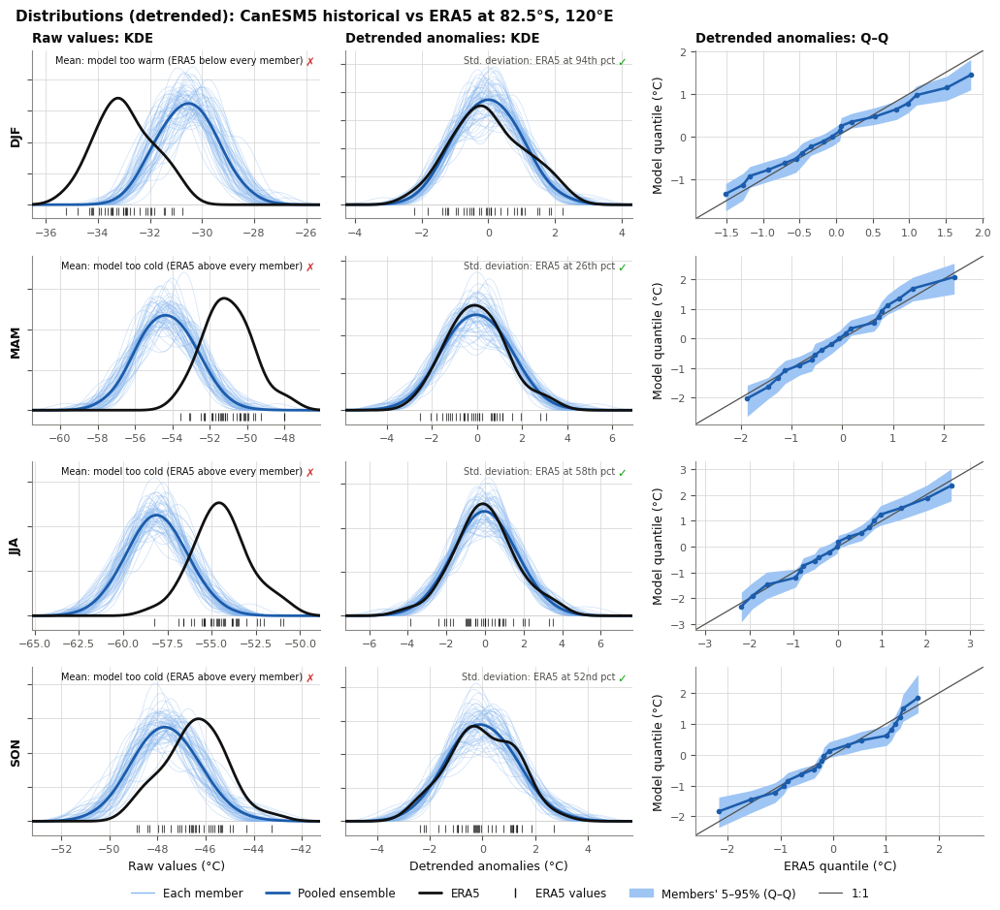

In [65]:
#(t): Detrended anomalies instead, to compare the noise alone: the raw values' KDEs, the detrended anomalies' KDEs and
#(t): Q-Q plot, seasons down
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=3, n_legends=1, panel_height=1.5),
                 layout='constrained')
axes = fig.add_gridspec(len(SEASONS), 3).subplots(squeeze=False)
for i, season in enumerate(SEASONS):
    evp.plot_kde(eval_distributions['raw'].sel(season=season), ax=axes[i, 0])
    evp.plot_kde(eval_distributions['detrended'].sel(season=season), ax=axes[i, 1])
    evp.plot_qq(eval_distributions['detrended'].sel(season=season), ax=axes[i, 2])
    for ax, treatment in zip(axes[i, :2], ['raw', 'detrended']):
        ok, message = evp.verdict(model_moments_ds.sel(season=season), evp.KDE_STATISTIC[treatment])
        evp.status_line(ax, 0.98, 0.97, ok, message, ha='right', fontsize=7)
        ax.tick_params(axis='y', labelleft=False)
    axes[i, 0].set_ylabel(season, fontweight='bold')
    axes[i, 2].set_ylabel(f'Model quantile ({VARIABLE.units})')

axes[0, 0].set_title(f"{ev.TREATMENTS['raw']}: KDE", loc='left')
axes[0, 1].set_title(f"{ev.TREATMENTS['detrended']}: KDE", loc='left')
axes[0, 2].set_title(f"{ev.TREATMENTS['detrended']}: Q–Q", loc='left')
axes[-1, 0].set_xlabel(f"{ev.TREATMENTS['raw']} ({VARIABLE.units})")
axes[-1, 1].set_xlabel(f"{ev.TREATMENTS['detrended']} ({VARIABLE.units})")
axes[-1, 2].set_xlabel(f'ERA5 quantile ({VARIABLE.units})')
fig.legend(handles=evp.distribution_legend_handles(), loc='outside lower center', ncols=6, frameon=False)
fig.suptitle(f'Distributions (detrended): {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

**What to look for**
- A raw-value KDE shifted from the ensemble is a mean-state bias. If the anomaly KDE then sits on top of the ensemble, the bias was the only problem.
- An anomaly KDE narrower or wider than the members' means the model has too much or too little variability. Check whether the std test (✓/✗) agrees.
- With ~35 values per season, a single ERA5 KDE is noisy. Judge it against the spread of the thin member curves, which have the same sample size, not against the smooth pooled curve.

## 3. Time Series: the Ensemble Plume

Blue bands are the ensemble's central 75% (12.5–87.5%, as in Suarez-Gutierrez et al., 2021), 5–95% and full range each year, with its median. ERA5 is black, with an orange ▲/▼ wherever it is above or below *every* member. If ERA5 were a member, that would happen 200 / (N + 1) % of the time (a few %), as noted in each panel. In the anomaly column, green outlines show the hist-nat ensemble for context.

In [66]:
#(t): EXAMPLE_MODEL's plume, raw values: the members' quantiles and range each year, and where ERA5 is
#(t): (ev.ensemble_plume)
eval_raw_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='raw')
eval_raw_plume_ds

<xarray.Dataset> Size: 11kB
Dimensions:           (season: 4, year: 35, quantile: 5)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 6kB -32.36 ... -45.28
    minimum           (year, season) float32 560B -33.47 -61.51 ... -56.39 -49.2
    maximum           (year, season) float32 560B -28.91 -55.62 ... -44.27
    obs               (year, season) float32 560B -32.97 -55.57 ... -43.27
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 1.0 1.0 0.0 ... 1.0 0.0 1.0
    central           (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [67]:
#(t): ... and anomalies
eval_anomaly_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='anomaly')
eval_anomaly_plume_ds

<xarray.Dataset> Size: 11kB
Dimensions:           (season: 4, year: 35, quantile: 5)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 6kB -1.897 ... 2.331
    minimum           (year, season) float32 560B -3.295 -3.451 ... -1.478
    maximum           (year, season) float32 560B 1.842 2.051 ... 3.859 3.305
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [68]:
#(t): The two along a treatment dim, on (treatment, quantile, year, season)
point_plume_ds = xr.concat([eval_raw_plume_ds, eval_anomaly_plume_ds], dim=xr.Variable('treatment', ['raw', 'anomaly']))
point_plume_ds

<xarray.Dataset> Size: 22kB
Dimensions:           (treatment: 2, quantile: 5, year: 35, season: 4)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
  * treatment         (treatment) <U7 56B 'raw' 'anomaly'
Data variables:
    quantiles         (treatment, quantile, year, season) float64 11kB -32.36...
    minimum           (treatment, year, season) float32 1kB -33.47 ... -1.478
    maximum           (treatment, year, season) float32 1kB -28.91 ... 3.305
    obs               (treatment, year, season) float32 1kB -32.97 ... 3.176
    below             (treatment, year, season) float64 2kB 0.0 0.0 ... 0.0 0.0
    above             (treatment, year, season) float64 2kB 0.0 1.0 ... 0.0 0.0
    central           (treatment, year, season) float64 2kB 0.0 0.0 ... 0.0 0.0
    n_members         (treatment) int64 16B 65 65
    expected_outside  (treatment) float64 16B 3.03 3.03
Attributes: (1)

In [69]:
#(t): The historical ensemble-mean climatology at the point: the mean over members and years, per season
point_hist_climatology_da = eval_members_da.mean(['member', 'year'])
point_hist_climatology_da

<xarray.DataArray 'tas' (season: 4)> Size: 16B
-30.56 -58.09 -54.3 -47.64
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lat      float64 8B -82.5
    lon      float64 8B 120.0

In [70]:
#(t): ERA5's climatology at the point, over the same years and missing-data mask
point_era5_climatology_da = eval_era5_da.mean('year')
point_era5_climatology_da

<xarray.DataArray 'tas' (season: 4)> Size: 16B
-32.97 -54.47 -51.02 -46.45
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lon      float64 8B 120.0
    lat      float64 8B -82.5

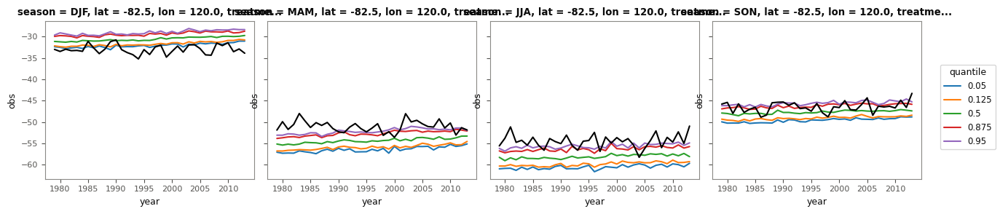

In [71]:
#(t): Quick look: the raw-value plume's quantiles (colours) and ERA5 (black), one panel per season
point_raw_plume_ds = point_plume_ds.sel(treatment='raw', season=SEASONS)
fg = point_raw_plume_ds['quantiles'].plot(x='year', hue='quantile', col='season')
for ax, season in zip(fg.axs.flat, SEASONS):
    point_raw_plume_ds['obs'].sel(season=season).plot(ax=ax, color='k')

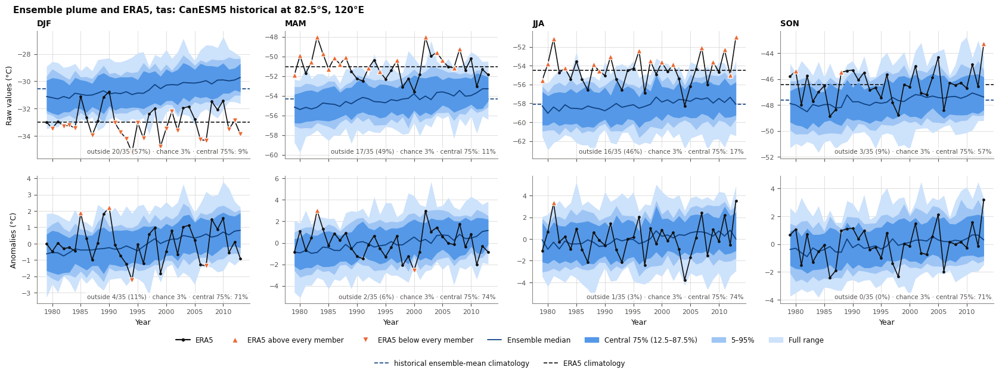

In [72]:
#(t): Raw values and anomalies (rows), seasons (columns): EXAMPLE_MODEL's plume and ERA5. Dashed: the two climatologies,
#(t): on the
#(t): raw values
plume_treatments = list(point_plume_ds['treatment'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(plume_treatments), n_cols=len(SEASONS), n_legends=2,
                                                  panel_width=3.6, panel_height=1.8), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(len(plume_treatments), len(SEASONS)).subplots(sharex=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for i, treatment in enumerate(plume_treatments):
    for j, season in enumerate(SEASONS):
        evp.plot_plume(point_plume_ds.sel(treatment=treatment, season=season), ax=axes[i, j])
    axes[i, 0].set_ylabel(f'{ev.TREATMENTS[treatment]} ({VARIABLE.units})')
for ax, season in zip(axes[0], SEASONS):
    ax.axhline(point_hist_climatology_da.sel(season=season), color=evp.ENSEMBLE['median'], lw=1.2, ls='--')
    ax.axhline(point_era5_climatology_da.sel(season=season), color=evp.ERA5_COLOR, lw=1.2, ls='--')
    ax.set_title(season, loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Year')
legend_axes[0].legend(handles=evp.plume_legend_handles(), loc='center', ncols=7, frameon=False)
legend_axes[1].legend(handles=[
    Line2D([], [], color=evp.ENSEMBLE['median'], lw=1.2, ls='--', label='historical ensemble-mean climatology'),
    Line2D([], [], color=evp.ERA5_COLOR, lw=1.2, ls='--', label='ERA5 climatology'),
], loc='center', ncols=2, frameon=False)
fig.suptitle(f'Ensemble plume and ERA5, {VARIABLE.name}: {EXAMPLE_MODEL} historical at {POINT_LABEL}', x=0.01,
             ha='left');

In [73]:
#(t): The plume: 0-100% in 5% steps, drawn as nested bands from the widest (0-100%) in
PLUME_QUANTILES = np.round(np.linspace(0, 1, 21), 2)
PLUME_PAIRS = np.column_stack([PLUME_QUANTILES[:10], PLUME_QUANTILES[::-1][:10]])
PLUME_PAIRS

array([[0.  , 1.  ],
       [0.05, 0.95],
       [0.1 , 0.9 ],
       [0.15, 0.85],
       [0.2 , 0.8 ],
       [0.25, 0.75],
       [0.3 , 0.7 ],
       [0.35, 0.65],
       [0.4 , 0.6 ],
       [0.45, 0.55]])

In [74]:
#(t): EXAMPLE_MODEL's plume and ERA5 at the point, raw values, on (quantile, year, season), at PLUME_QUANTILES
point_raw_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='raw', quantiles=PLUME_QUANTILES)
point_raw_plume_ds

<xarray.Dataset> Size: 29kB
Dimensions:           (season: 4, year: 35, quantile: 21)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 24kB -33.47 ... -44.27
    minimum           (year, season) float32 560B -33.47 -61.51 ... -56.39 -49.2
    maximum           (year, season) float32 560B -28.91 -55.62 ... -44.27
    obs               (year, season) float32 560B -32.97 -55.57 ... -43.27
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 1.0 1.0 0.0 ... 1.0 0.0 1.0
    central           (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [75]:
#(t): The same for anomalies: each member and ERA5 minus its own mean in each season
point_anomaly_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='anomaly', quantiles=PLUME_QUANTILES)
point_anomaly_plume_ds

<xarray.Dataset> Size: 29kB
Dimensions:           (season: 4, year: 35, quantile: 21)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 24kB -3.295 ... 3.305
    minimum           (year, season) float32 560B -3.295 -3.451 ... -1.478
    maximum           (year, season) float32 560B 1.842 2.051 ... 3.859 3.305
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [76]:
#(t): Each season's middle month, as a fraction of a year
#(c): DJF is labelled by its December's year, so its middle month (January) is in the next year
SEASON_MIDDLE = xr.DataArray([12.5, 3.5, 6.5, 9.5], coords={'season': ['DJF', 'MAM', 'JJA', 'SON']}) / 12


def seasons_in_time(obj):
    """Put (year, season) on one time axis, in decimal years at each season's middle month.

    year and season stay as coordinates along time, so a seasonal climatology can be
    looked up at every time step with .sel(season=...), like the old day-of-year lookup.

    Args:
        obj (xr.Dataset | xr.DataArray): Data on (year, season, ...).

    Returns:
        The same on (time, ...), time in decimal years, sorted; DJF 1980 is at 1981.04 (January 1981).
    """
    decimal_year_da = obj['year'] + SEASON_MIDDLE.sel(season=obj['season'])
    with_time = obj.assign_coords(time=decimal_year_da)
    stacked = with_time.stack(sample=['year', 'season'])
    stacked = stacked.reset_index('sample')        # year and season become plain coordinates
    stacked = stacked.swap_dims(sample='time')
    return stacked.sortby('time')

In [77]:
#(t): The raw-value plume on one time axis
point_raw_plume_time_ds = seasons_in_time(point_raw_plume_ds)
point_raw_plume_time_ds

<xarray.Dataset> Size: 33kB
Dimensions:           (quantile: 21, time: 140)
Coordinates:
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
  * time              (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03
    year              (time) int64 1kB 1979 1979 1979 1979 ... 2013 2013 2013
    season            (time) <U3 2kB 'MAM' 'JJA' 'SON' ... 'JJA' 'SON' 'DJF'
Data variables:
    quantiles         (quantile, time) float64 24kB -58.74 -61.51 ... -28.18
    minimum           (time) float32 560B -58.74 -61.51 -51.31 ... -49.2 -31.63
    maximum           (time) float32 560B -52.34 -55.62 -44.79 ... -44.27 -28.18
    obs               (time) float32 560B -51.88 -55.57 -45.79 ... -43.27 -33.87
    below             (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 1.0
    above             (time) float64 1kB 1.0 1.0 0.0 0.0 1.0 ... 0.0 1.0 1.0 0.0
    central           (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [78]:
#(t): Check: the times are in order, one per season, and DJF 1980 sits at January 1981 (1981 + 0.5 / 12 = 1981.042)
raw_times_index = point_raw_plume_time_ds.indexes['time']
djf_1980_arr = raw_times_index[(point_raw_plume_time_ds['season'].values == 'DJF')
                               & (point_raw_plume_time_ds['year'].values == 1980)].values
(raw_times_index.is_monotonic_increasing, len(raw_times_index) == point_raw_plume_ds.sizes['year'] * 4,
 djf_1980_arr.round(3))

(True, True, array([1981.042]))

In [79]:
#(t): The anomaly plume on one time axis
point_anomaly_plume_time_ds = seasons_in_time(point_anomaly_plume_ds)
point_anomaly_plume_time_ds

<xarray.Dataset> Size: 33kB
Dimensions:           (quantile: 21, time: 140)
Coordinates:
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
  * time              (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03
    year              (time) int64 1kB 1979 1979 1979 1979 ... 2013 2013 2013
    season            (time) <U3 2kB 'MAM' 'JJA' 'SON' ... 'JJA' 'SON' 'DJF'
Data variables:
    quantiles         (quantile, time) float64 24kB -4.601 -3.451 ... 2.238
    minimum           (time) float32 560B -4.601 -3.451 ... -1.478 -0.9785
    maximum           (time) float32 560B 2.069 2.051 2.603 ... 4.91 3.305 2.238
    obs               (time) float32 560B -0.8627 -1.103 ... 3.176 -0.9004
    below             (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    above             (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    central           (time) float64 1kB 1.0 1.0 1.0 1.0 0.0 ... 0.0 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [80]:
#(t): The historical climatology at every time step, looked up by season
point_hist_climatology_time_da = point_hist_climatology_da.sel(season=point_raw_plume_time_ds['season'])
point_hist_climatology_time_da

<xarray.DataArray 'tas' (time: 140)> Size: 560B
-54.3 -58.09 -47.64 -30.56 -54.3 -58.09 ... -30.56 -54.3 -58.09 -47.64 -30.56
Coordinates:
    season   (time) object 1kB 'MAM' 'JJA' 'SON' 'DJF' ... 'JJA' 'SON' 'DJF'
    lat      float64 8B -82.5
    lon      float64 8B 120.0
  * time     (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03 2.014e+03
    year     (time) int64 1kB 1979 1979 1979 1979 1980 ... 2013 2013 2013 2013

In [81]:
#(t): ERA5's climatology at every time step, looked up by season
point_era5_climatology_time_da = point_era5_climatology_da.sel(season=point_raw_plume_time_ds['season'])
point_era5_climatology_time_da

<xarray.DataArray 'tas' (time: 140)> Size: 560B
-51.02 -54.47 -46.45 -32.97 -51.02 -54.47 ... -32.97 -51.02 -54.47 -46.45 -32.97
Coordinates:
    season   (time) object 1kB 'MAM' 'JJA' 'SON' 'DJF' ... 'JJA' 'SON' 'DJF'
    lon      float64 8B 120.0
    lat      float64 8B -82.5
  * time     (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03 2.014e+03
    year     (time) int64 1kB 1979 1979 1979 1979 1980 ... 2013 2013 2013 2013

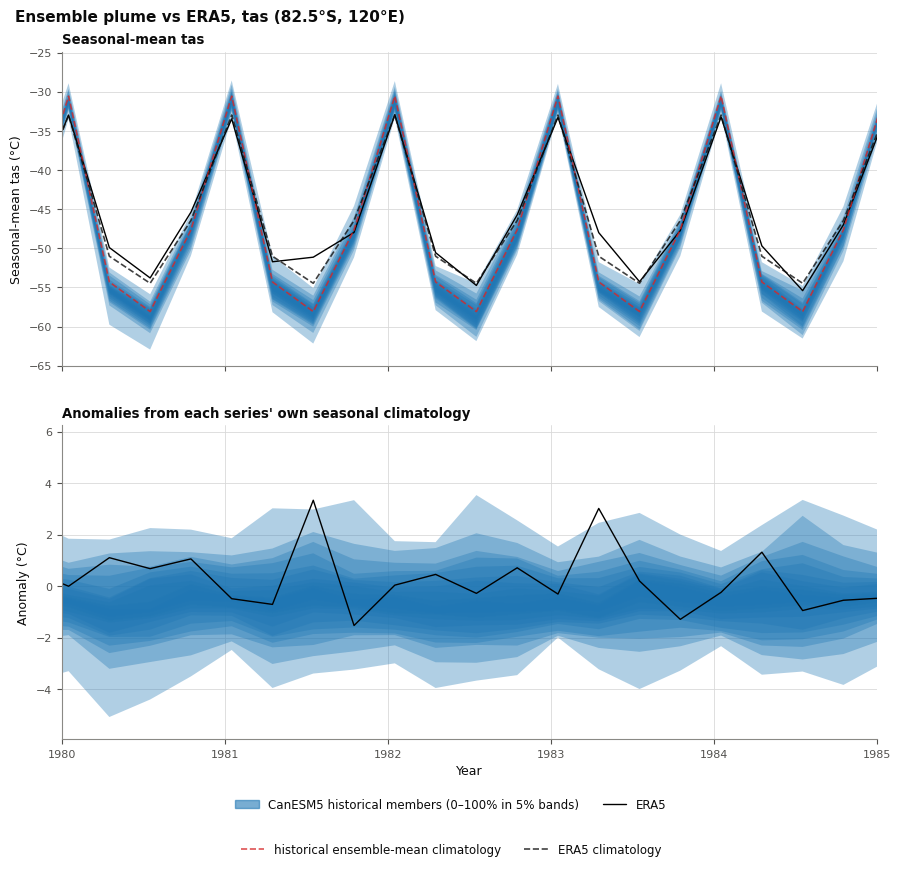

In [82]:
#(t): EXAMPLE_MODEL's plume (0-100% in 5% bands, PLUME_PAIRS, each band drawn over the last) and ERA5, on one time axis:
#(t): the
#(t): raw values with the two climatologies (top), and the anomalies (bottom); 1980-1985 shown
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=2, n_cols=1, n_legends=2, panel_width=8.0, panel_height=3.0),
                 layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(2, 1).subplots(sharex=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for ax, plume_time_ds in zip(axes[:, 0], [point_raw_plume_time_ds, point_anomaly_plume_time_ds]):
    charts.plot_quantile_bands(plume_time_ds['quantiles'], PLUME_PAIRS, 'time', ax=ax, color='C0', alpha=0.35)
    charts.plot_lines(plume_time_ds['obs'], 'time', ax=ax, color='k', linewidth=1)
charts.plot_lines(point_hist_climatology_time_da, 'time', ax=axes[0, 0], color='C3', linewidth=1.2, linestyle='--',
                  alpha=0.8)
charts.plot_lines(point_era5_climatology_time_da, 'time', ax=axes[0, 0], color=evp.ERA5_COLOR, linewidth=1.2,
                  linestyle='--', alpha=0.8)

axes[0, 0].set_title(f'Seasonal-mean {VARIABLE.name}', loc='left')
axes[0, 0].set_ylabel(f'Seasonal-mean {VARIABLE.name} ({VARIABLE.units})')
axes[1, 0].set_title("Anomalies from each series' own seasonal climatology", loc='left')
axes[1, 0].set_ylabel(f'Anomaly ({VARIABLE.units})')
axes[1, 0].set_xlabel('Year')
#(c): The x axis is shared: its range set once
axes[0, 0].set_xlim(1980, 1985)
legend_axes[0].legend(handles=[Patch(color='C0', alpha=0.6,
                                     label=f'{EXAMPLE_MODEL} historical members (0–100% in 5% bands)'),
                               Line2D([], [], color='k', lw=1, label='ERA5')], loc='center', ncols=2, frameon=False)
legend_axes[1].legend(handles=[
    Line2D([], [], color='C3', lw=1.2, ls='--', alpha=0.8, label='historical ensemble-mean climatology'),
    Line2D([], [], color=evp.ERA5_COLOR, lw=1.2, ls='--', alpha=0.8, label='ERA5 climatology'),
], loc='center', ncols=2, frameon=False)
fig.suptitle(f'Ensemble plume vs ERA5, {VARIABLE.name} ({POINT_LABEL})', x=0.01, ha='left');

In [83]:
#(t): hist-nat's anomaly plume at the point, as context: ERA5 should follow historical, not hist-nat
histnat_plume_ds = ev.ensemble_plume(histnat_point_tree[EXAMPLE_MODEL]['hist-nat']['tas'], era5_point_da,
                                     treatment='anomaly')
histnat_plume_ds

<xarray.Dataset> Size: 11kB
Dimensions:           (season: 4, year: 35, quantile: 5)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 6kB -1.653 ... 1.459
    minimum           (year, season) float32 560B -2.543 -2.355 ... -2.982
    maximum           (year, season) float32 560B 1.735 3.383 ... 2.685 2.784
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 1.0 0.0 1.0
    central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 1.0 0.0
    n_members         int64 8B 50
    expected_outside  float64 8B 3.922
Attributes: (1)

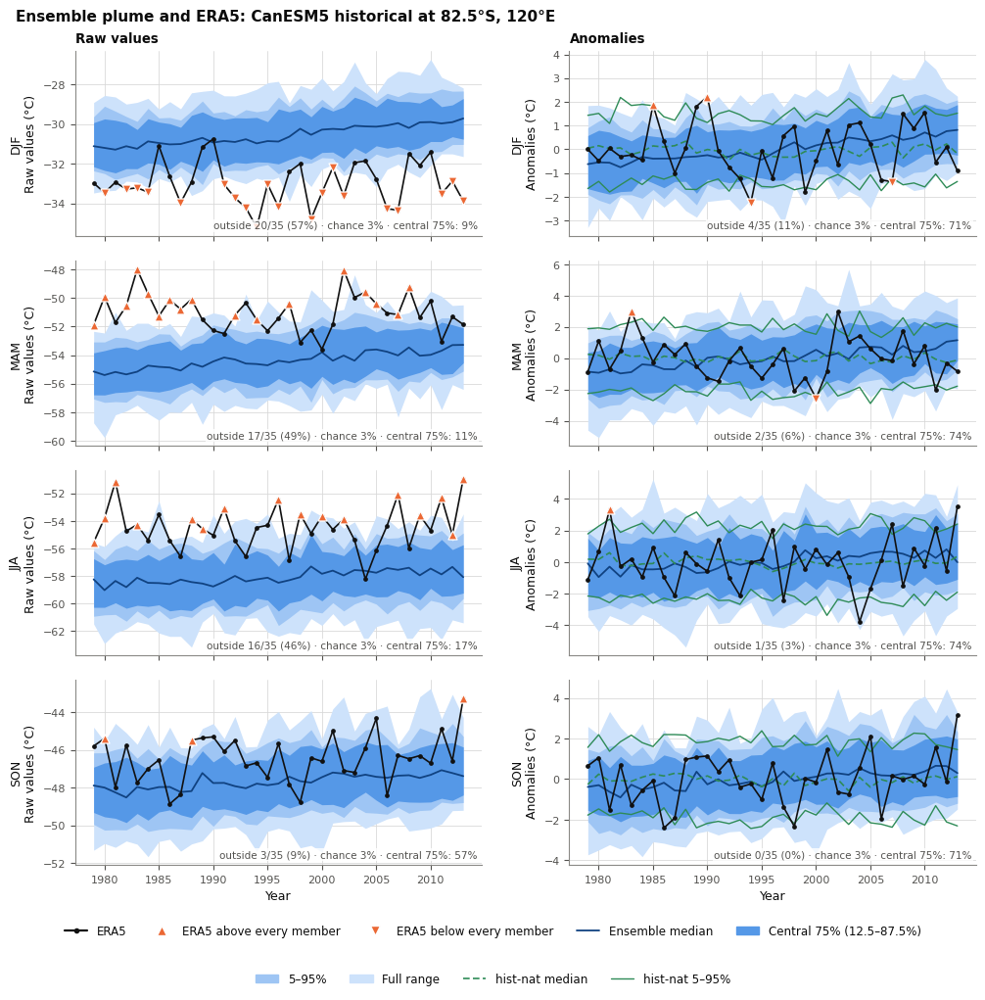

In [84]:
#(t): One model: seasons (rows) × raw values and anomalies (columns), with hist-nat (green) for context on the
#(t): anomalies, which is what it has
plume_treatments = list(point_plume_ds['treatment'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=len(plume_treatments), n_legends=2,
                                                  panel_width=4.3, panel_height=1.6), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(len(SEASONS), len(plume_treatments)).subplots(sharex=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for i, season in enumerate(SEASONS):
    for j, treatment in enumerate(plume_treatments):
        context_ds = histnat_plume_ds.sel(season=season) if treatment == 'anomaly' else None
        evp.plot_plume(point_plume_ds.sel(season=season, treatment=treatment), ax=axes[i, j], context=context_ds)
        axes[i, j].set_ylabel(f'{season}\n{ev.TREATMENTS[treatment]} ({VARIABLE.units})')
for ax, treatment in zip(axes[0], plume_treatments):
    ax.set_title(ev.TREATMENTS[treatment], loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Year')
plume_handles = evp.plume_legend_handles(context=True)
legend_axes[0].legend(handles=plume_handles[:5], loc='center', ncols=5, frameon=False)
legend_axes[1].legend(handles=plume_handles[5:], loc='center', ncols=4, frameon=False)
fig.suptitle(f'Ensemble plume and ERA5: {EXAMPLE_MODEL} historical at {POINT_LABEL}', x=0.01, ha='left');

In [85]:
#(t): Every model's anomaly plume (ev.ensemble_plume of each model's members, against ERA5)
all_plumes_tree = xr.DataTree.from_dict({
    node.path: ev.ensemble_plume(node['tas'], era5_point_da, treatment='anomaly') for node in historical_point_tree.leaves
})
all_plumes_tree

<xarray.DataTree>
Group: /
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:           (year: 35, season: 4, quantile: 5)
│           Coordinates:
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
│               lat               float64 8B -82.5
│               lon               float64 8B 120.0
│           Data variables:
│               quantiles         (quantile, year, season) float64 6kB -1.918 ... 2.135
│               minimum           (year, season) float32 560B -3.12 -3.93 ... -4.077 -2.463
│               maximum           (year, season) float32 560B 2.761 2.62 ... 7.445 3.691
│               obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
│               below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               central           (year, season) float64 1kB 1.0 1.0 1.0 0.0 ... 0.0 0.0 0.0
│               n_members         int64 8B 63
│               expected_outside  float64 8B 3.125
│           Attributes: (1)
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:           (season: 4, year: 35, quantile: 5)
│           Coordinates:
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│             * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
│               lat               float64 8B -82.5
│               lon               float64 8B 120.0
│           Data variables:
│               quantiles         (quantile, year, season) float64 6kB -1.897 ... 2.331
│               minimum           (year, season) float32 560B -3.295 -3.451 ... -1.478
│               maximum           (year, season) float32 560B 1.842 2.051 ... 3.859 3.305
│               obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
│               below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
│               n_members         int64 8B 65
│               expected_outside  float64 8B 3.03
│           Attributes: (1)
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:           (year: 35, season: 4, quantile: 5)
│           Coordinates:
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
│               lat               float64 8B -82.5
│               lon               float64 8B 120.0
│           Data variables:
│               quantiles         (quantile, year, season) float64 6kB -1.231 ... 1.73
│               minimum           (year, season) float32 560B -2.015 -4.351 ... -3.384 -3.1
│               maximum           (year, season) float32 560B 2.362 2.909 ... 5.772 2.92
│               obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
│               below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 1.0 0.0 1.0
│               central           (year, season) float64 1kB 1.0 1.0 1.0 0.0 ... 0.0 1.0 0.0
│               n_members         int64 8B 50
│               expected_outside  float64 8B 3.922
│           Attributes: (1)
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensio

In [86]:
#(t): Without the members, so they fit side by side on (model, quantile, year, season)
all_plumes_ds = tree_to_dataset(all_plumes_tree, dims=['model', 'experiment'])
all_plumes_ds = all_plumes_ds.sel(experiment='historical', drop=True)
all_plumes_ds

<xarray.Dataset> Size: 64kB
Dimensions:           (model: 6, quantile: 5, year: 35, season: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season, model) float64 34kB -1.897 ......
    minimum           (year, season, model) float32 3kB -3.295 -3.12 ... -2.351
    maximum           (year, season, model) float32 3kB 1.842 2.761 ... 2.629
    obs               (year, season, model) float32 3kB -0.0005684 ... 3.176
    below             (year, season, model) float64 7kB 0.0 0.0 0.0 ... 0.0 0.0
    above             (year, season, model) float64 7kB 0.0 0.0 0.0 ... 0.0 1.0
    central           (year, season, model) float64 7kB 1.0 1.0 1.0 ... 0.0 0.0
    n_members         (model) int64 48B 65 63 55 50 51 43
    expected_outside  (model) float64 48B 3.03 3.125 3.571 3.922 3.846 4.545
Attributes: (1)

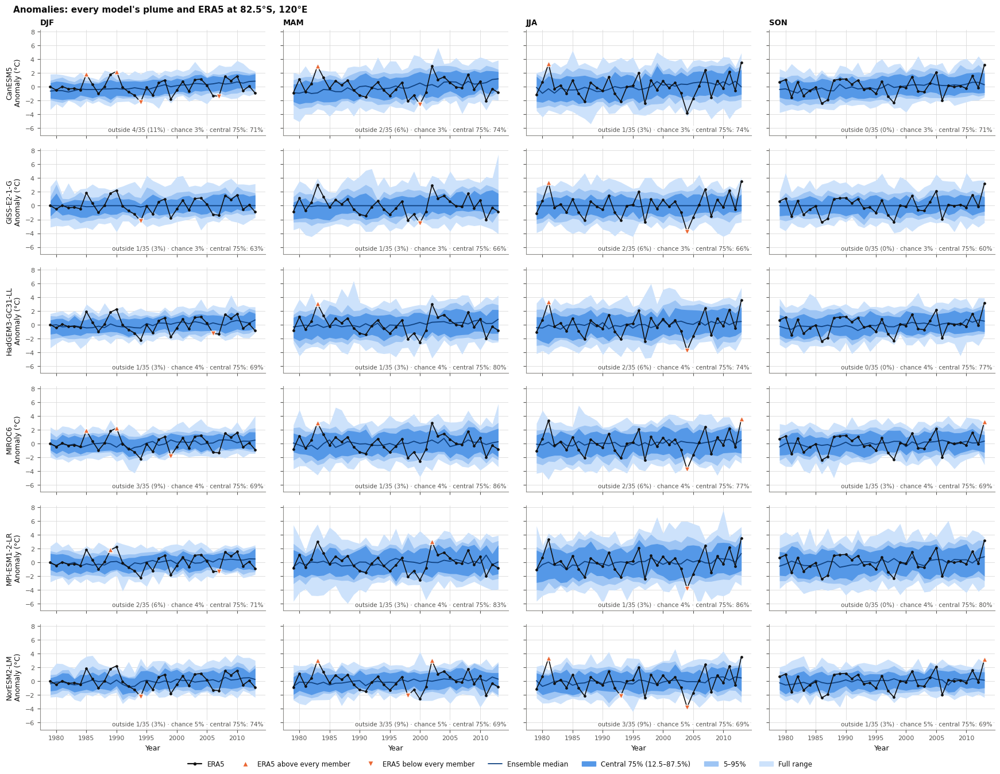

In [87]:
#(t): Anomalies: every model's plume (rows) and ERA5, seasons across, on one y scale
plume_models = list(all_plumes_ds['model'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(plume_models), n_cols=len(SEASONS), n_legends=1,
                                                  panel_width=3.6, panel_height=1.5, left_margin=1.4),
                 layout='constrained')
axes = fig.add_gridspec(len(plume_models), len(SEASONS)).subplots(sharex=True, sharey=True, squeeze=False)
for i, model in enumerate(plume_models):
    for j, season in enumerate(SEASONS):
        evp.plot_plume(all_plumes_ds.sel(model=model, season=season), ax=axes[i, j])
    axes[i, 0].set_ylabel(f'{model}\nAnomaly ({VARIABLE.units})')
for ax, season in zip(axes[0], SEASONS):
    ax.set_title(season, loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Year')
fig.legend(handles=evp.plume_legend_handles(), loc='outside lower center', ncols=7, frameon=False)
fig.suptitle(f"Anomalies: every model's plume and ERA5 at {POINT_LABEL}", x=0.01, ha='left');

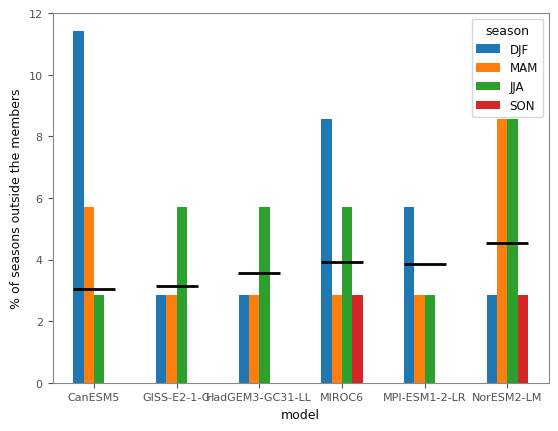

In [88]:
#(t): % of seasons with ERA5 outside each model's range (bars), against chance, 200 / (N + 1) % (black)
outside_ds = ev.outside_frequency(all_plumes_ds)
outside_df = outside_ds['outside'].sel(season=SEASONS).transpose('model', 'season').to_pandas()
ax = outside_df.plot.bar(rot=0, ylabel='% of seasons outside the members')
ax.plot(range(len(outside_df)), outside_ds['expected_outside'].to_pandas().values, 'k_', ms=30, mew=2);

**What to look for**
- Raw values outside the plume in most years, with anomalies inside it: a mean-state bias only.
- Anomalies outside the plume *at both extremes* more often than chance: too little noise, or a signal problem (which one is settled in section 5).
- ERA5 drifting from one edge of the anomaly plume towards the other through the record: the trend differs (the signal).

## 4. Moment Test and Other Statistics

Each panel is one statistic in one season: every member's value is a blue dot, the shading the members' 5–95%, ERA5 the black line and diamond. If the model were perfect, ERA5 would be just another dot; it is flagged (✗) when it falls outside the shading.

In [89]:
#(t): EXAMPLE_MODEL's tests
eval_moments_ds = moment_test_tree[EXAMPLE_MODEL]['historical'].to_dataset()
eval_statistics_ds = statistic_test_tree[EXAMPLE_MODEL]['historical'].to_dataset()
eval_statistics_ds

<xarray.Dataset> Size: 10kB
Dimensions:     (statistic: 4, season: 4, member: 65)
Coordinates:
    lat         float64 8B -82.5
    lon         float64 8B 120.0
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * statistic   (statistic) <U10 160B 'trend' 'width' 'lower_tail' 'upper_tail'
    treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
Data variables:
    era5        (statistic, season) float64 128B 0.01296 0.1282 ... 2.271 1.786
    members     (statistic, member, season) float64 8kB -0.04846 ... 1.522
    lower       (statistic, season) float64 128B 0.1112 -0.1618 ... 1.373 1.304
    median      (statistic, season) float64 128B 0.4332 0.3684 ... 2.072 1.904
    upper       (statistic, season) float64 128B 0.6944 0.7645 ... 2.794 2.799
    percentile  (statistic, season) float64 128B 1.538 21.54 0.0 ... 66.15 40.0
    pvalue      (statistic, season) float64 128B 0.06061 0.4545 ... 0.697 0.8182
    verdict     (statistic, season) float64 128B -1.0 0.0 -1.0 ... 0.0 0.0 0.0
    testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0

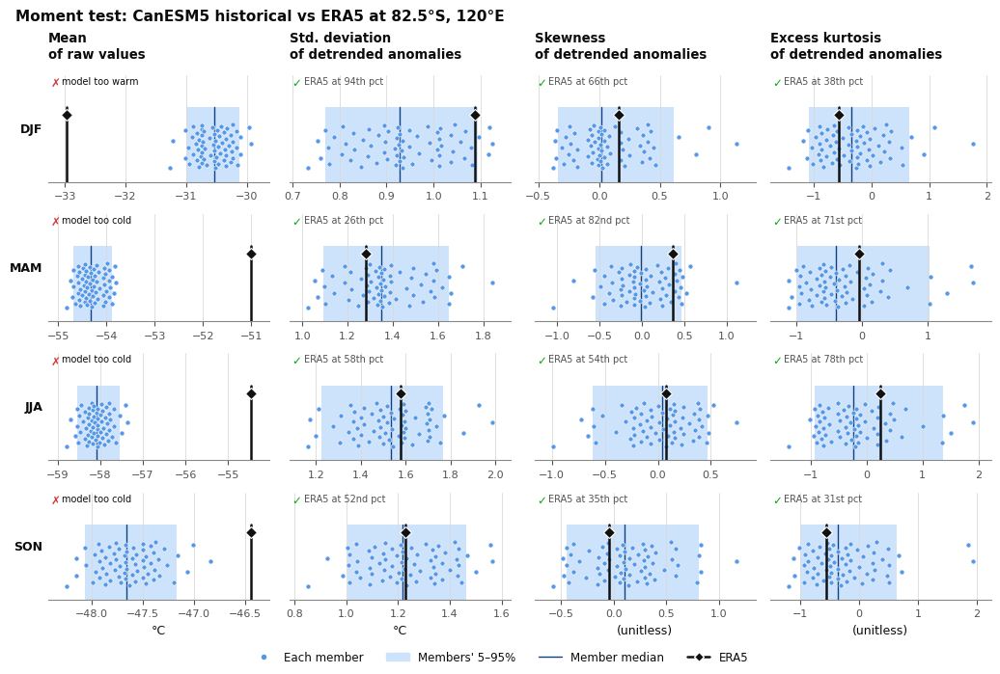

In [90]:
#(t): The moment test: each statistic (columns) in each season (rows), every member a dot and ERA5 the black line, with
#(t): each panel's verdict
moment_statistics = list(eval_moments_ds['statistic'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=len(moment_statistics), n_legends=1,
                                                  panel_width=2.0, panel_height=0.9), layout='constrained')
axes = fig.add_gridspec(len(SEASONS), len(moment_statistics)).subplots(squeeze=False)
evp.member_strips_grid(eval_moments_ds.sel(season=SEASONS), 'season', axes=axes)
for ax, statistic in zip(axes[0], moment_statistics):
    ax.set_title(evp.statistic_title(eval_moments_ds, statistic), loc='left', pad=13)
for ax, statistic in zip(axes[-1], moment_statistics):
    ax.set_xlabel(ev.DIAGNOSTICS[statistic].units or '(unitless)')
for ax, season in zip(axes[:, 0], SEASONS):
    ax.set_ylabel(season, rotation=0, ha='right', va='center', fontweight='bold')
fig.legend(handles=evp.member_strip_legend_handles(), loc='outside lower center', ncols=4, frameon=False)
fig.suptitle(f'Moment test: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

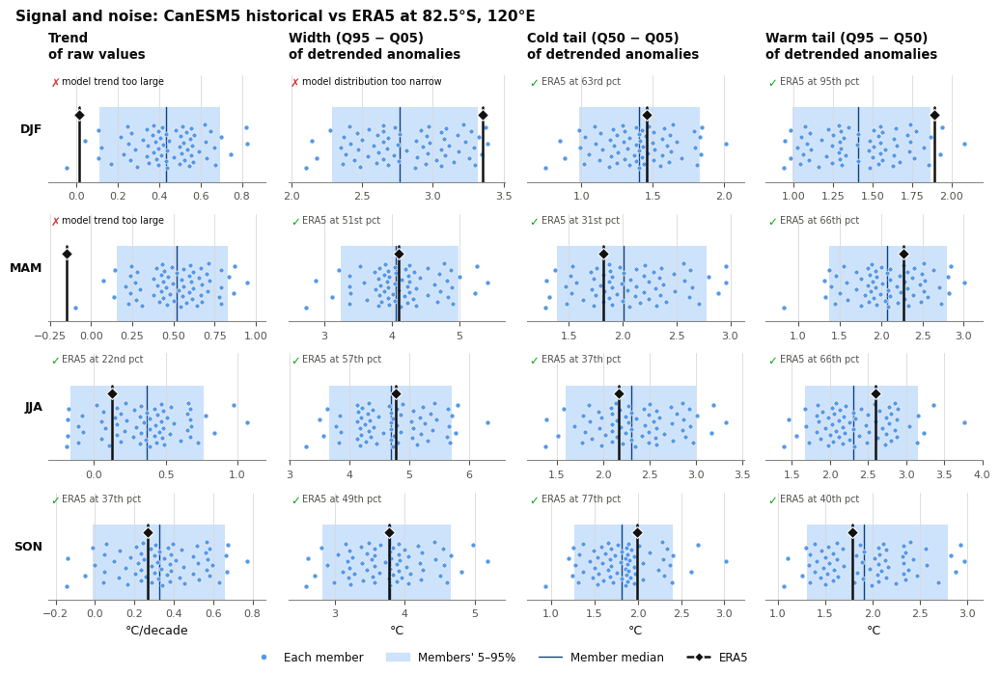

In [91]:
#(t): The signal and noise statistics (the quantities the response figures use)
signal_statistics = ['trend', 'width', 'lower_tail', 'upper_tail']
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=len(signal_statistics), n_legends=1,
                                                  panel_width=2.0, panel_height=0.9), layout='constrained')
axes = fig.add_gridspec(len(SEASONS), len(signal_statistics)).subplots(squeeze=False)
evp.member_strips_grid(eval_statistics_ds.sel(season=SEASONS), 'season', axes=axes, statistics=signal_statistics)
for ax, statistic in zip(axes[0], signal_statistics):
    ax.set_title(evp.statistic_title(eval_statistics_ds, statistic), loc='left', pad=13)
for ax, statistic in zip(axes[-1], signal_statistics):
    ax.set_xlabel(ev.DIAGNOSTICS[statistic].units or '(unitless)')
for ax, season in zip(axes[:, 0], SEASONS):
    ax.set_ylabel(season, rotation=0, ha='right', va='center', fontweight='bold')
fig.legend(handles=evp.member_strip_legend_handles(), loc='outside lower center', ncols=4, frameon=False)
fig.suptitle(f'Signal and noise: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

## 5. Rank Histograms (Suarez-Gutierrez et al., 2021)

calc_03b goes through the test step by step. Bars are ERA5's rank frequencies; the dashed lines bound the pseudo-observations', the range a perfect model's histogram falls in. A U shape means too little spread (or a wrong trend pushing ERA5 out at both ends), a dome too much. The same U in anomalies and detrended anomalies is a noise problem; a U in anomalies only is a signal problem.

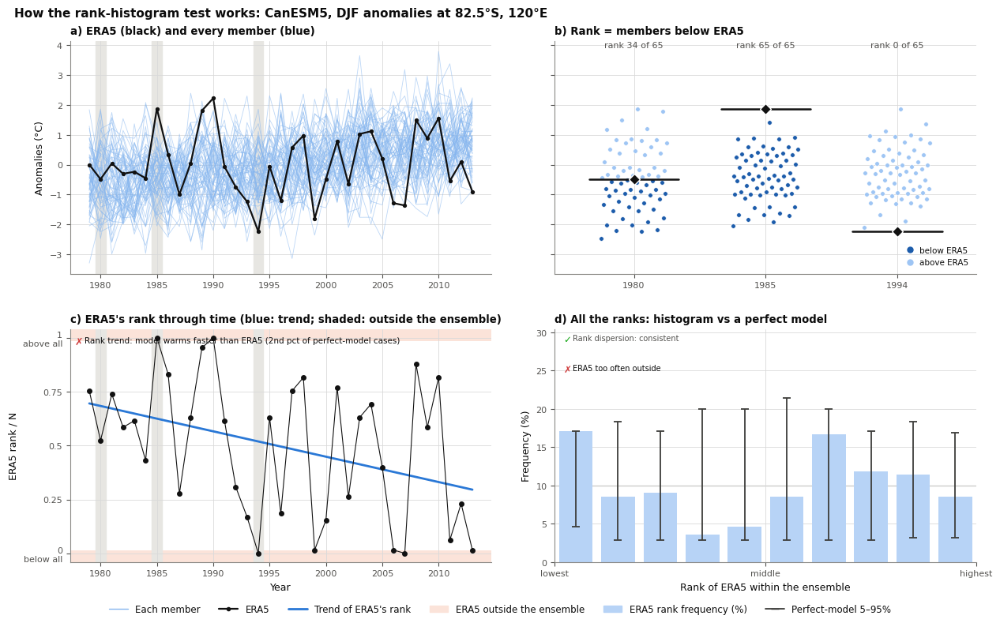

In [92]:
#(t): How the rank-histogram test works, for EXAMPLE_MODEL's anomalies at the point in the example season: a) ERA5 and
#(t): the members through time,
#(t): three instructive years shaded; b) in those years, ERA5's rank is the number of members below it; c) ERA5's rank
#(t): through the record, and its trend; d) every year's rank, counted into a histogram, against a perfect model's
anatomy_members_da = rank_anatomy_ds['members']
anatomy_era5_da = rank_anatomy_ds['era5']
highlighted_years = evp.anatomy_years(anatomy_result_ds)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=2, n_cols=2, n_legends=1, panel_width=5.6, panel_height=2.8),
                 layout='constrained')
axes = fig.add_gridspec(2, 2).subplots(squeeze=False)

#(c): a) the members and ERA5, with the three years shaded
charts.plot_lines(anatomy_members_da, 'year', ax=axes[0, 0], color=evp.ENSEMBLE['member'], linewidth=0.6, alpha=0.55)
charts.plot_lines(anatomy_era5_da, 'year', ax=axes[0, 0], color=evp.ERA5_COLOR, linewidth=1.6, marker='o',
                  markersize=2.8, zorder=3)
for year in highlighted_years:
    axes[0, 0].axvspan(year - 0.45, year + 0.45, color='#e7e6e2', zorder=0)
treatment = str(anatomy_result_ds['treatment'].values[0])
axes[0, 0].set_ylabel(f'{ev.TREATMENTS[treatment]} ({VARIABLE.units})')
axes[0, 0].set_title('a) ERA5 (black) and every member (blue)', loc='left')
#(c): b) ranking ERA5 in each of the three years
evp.plot_rank_counting(anatomy_members_da, anatomy_era5_da, highlighted_years, ax=axes[0, 1])
#(c): On a's y axis, so each year's values line up with a's
axes[0, 1].sharey(axes[0, 0])
axes[0, 1].tick_params(axis='y', labelleft=False)
axes[0, 1].set_title('b) Rank = members below ERA5', loc='left')
#(c): c) ERA5's rank through time
evp.plot_rank_through_time(anatomy_result_ds, highlighted_years, ax=axes[1, 0])
axes[1, 0].set_ylabel('ERA5 rank / N')
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_title("c) ERA5's rank through time (blue: trend; shaded: outside the ensemble)", loc='left')
#(c): d) all the ranks, in 10 bins of rank / N (~35 ranks over N bins would be sparse)
evp.plot_grouped_rank_histogram(anatomy_result_ds, ax=axes[1, 1], n_bins=10, statistics=('dispersion', 'outside'))
axes[1, 1].set_ylabel('Frequency (%)')
axes[1, 1].set_xlabel('Rank of ERA5 within the ensemble')
axes[1, 1].set_title('d) All the ranks: histogram vs a perfect model', loc='left')

fig.legend(handles=[
Line2D([], [], color=evp.ENSEMBLE['member'], lw=1, label='Each member'),
Line2D([], [], color=evp.ERA5_COLOR, lw=1.6, marker='o', ms=3, label='ERA5'),
Line2D([], [], color=evp.RANK_LINE, lw=2, label="Trend of ERA5's rank"),
Patch(color='#fbe3d9', label='ERA5 outside the ensemble'),
*evp.grouped_rank_legend_handles()[:2],
], loc='outside lower center', ncols=6, frameon=False)
anatomy_season = str(anatomy_members_da['season'].values)
fig.suptitle(f'How the rank-histogram test works: {EXAMPLE_MODEL}, {anatomy_season} anomalies at {POINT_LABEL}', x=0.01,
             ha='left');

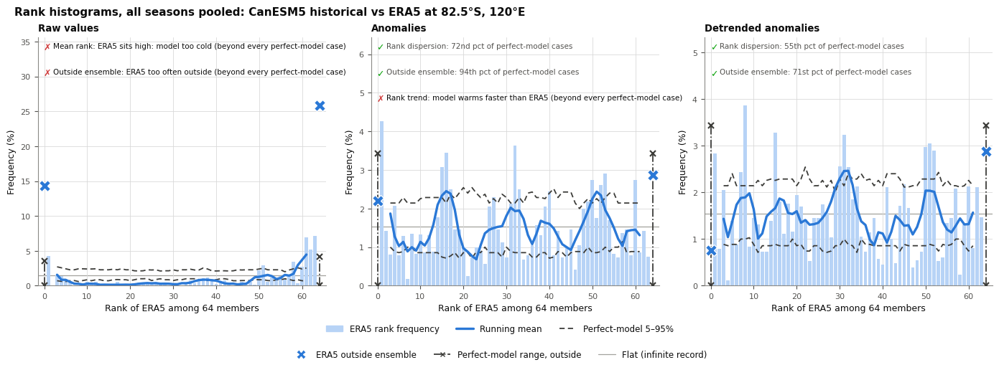

In [93]:
#(t): All four seasons pooled: EXAMPLE_MODEL's rank histograms of the raw values, the anomalies and the detrended
#(t): anomalies,
#(t): side by side, each with its verdicts
model_ranks = {'Raw values': raw_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset(),
               'Anomalies': anomaly_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset(),
               'Detrended anomalies': detrended_ranks_tree[EXAMPLE_MODEL]['historical'].to_dataset()}
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(model_ranks), n_legends=2, panel_width=4.0,
                                                  panel_height=3.0), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(1, len(model_ranks)).subplots(squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for ax, (label, ranks_ds) in zip(axes[0], model_ranks.items()):
    evp.plot_rank_histogram(ranks_ds, ax=ax)
    ax.set_title(label, loc='left')
rank_handles = evp.rank_histogram_legend_handles()
legend_axes[0].legend(handles=rank_handles[:3], loc='center', ncols=3, frameon=False)
legend_axes[1].legend(handles=rank_handles[3:], loc='center', ncols=3, frameon=False)
fig.suptitle(f'Rank histograms, all seasons pooled: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01,
             ha='left');

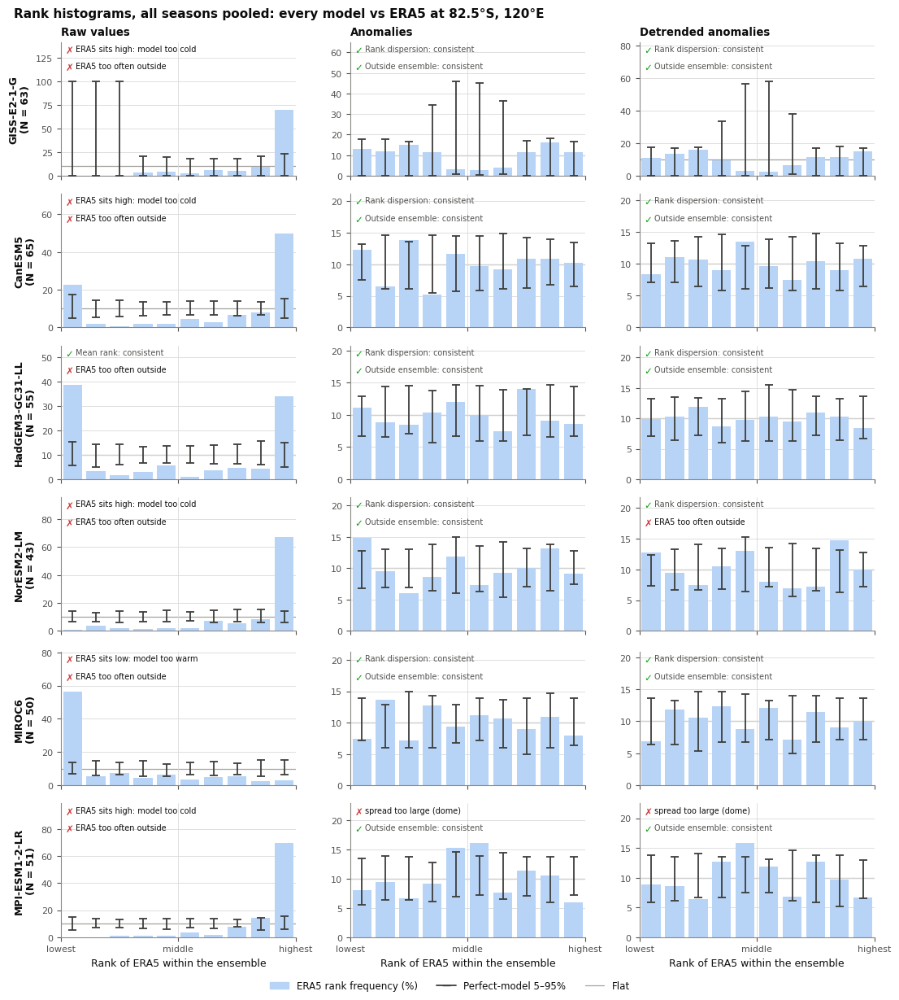

In [94]:
#(t): Every model (rows), compact: ranks grouped into 10 bins of rank / N, so ensembles of any size line up; raw values,
#(t): anomalies and detrended anomalies across
rank_trees = {'Raw values': raw_ranks_tree, 'Anomalies': anomaly_ranks_tree, 'Detrended anomalies': detrended_ranks_tree}
rank_models = [node.parent.name for node in raw_ranks_tree.match('*/historical').leaves]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(rank_models), n_cols=len(rank_trees), n_legends=1,
                                                  panel_width=2.8, panel_height=1.3, left_margin=1.5),
                 layout='constrained')
axes = fig.add_gridspec(len(rank_models), len(rank_trees)).subplots(sharex=True, squeeze=False)
for i, model in enumerate(rank_models):
    for j, ranks_tree in enumerate(rank_trees.values()):
        evp.plot_grouped_rank_histogram(ranks_tree[model]['historical'].to_dataset(), ax=axes[i, j])
    n_members = raw_ranks_tree[model]['historical'].attrs['n_members']
    axes[i, 0].set_ylabel(f'{model}\n(N = {n_members})', fontweight='bold')
for ax, label in zip(axes[0], rank_trees):
    ax.set_title(label, loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Rank of ERA5 within the ensemble')
fig.legend(handles=evp.grouped_rank_legend_handles(), loc='outside lower center', ncols=3, frameon=False)
fig.suptitle(f'Rank histograms, all seasons pooled: every model vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

## 6. Every Model: Scorecard and Signal vs Noise

**Scorecard.** Colour is ERA5's percentile among that model's members: blue, ERA5 below most members; red, above. Outlined cells are flagged (p < 0.1). Expect about one cell in ten flagged by chance: trust patterns over single cells.

**Signal vs noise.** ERA5's percentile for the trend (x: the signal) against the standard deviation of detrended anomalies (y: the noise). Inside the grey square the model is consistent on both.

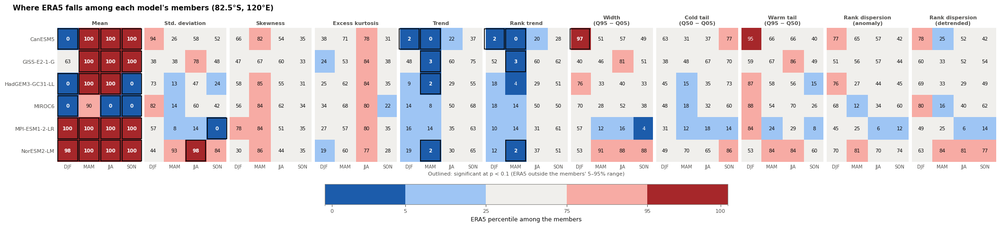

In [95]:
#(t): Every model (rows), statistic and season (columns): ERA5's percentile among the members, outlined where
#(t): significant
SCORECARD_STATISTICS = ['mean', 'std', 'skewness', 'kurtosis', 'trend', 'rank_trend', 'width',
                        'lower_tail', 'upper_tail', 'dispersion (anomaly)', 'dispersion (detrended)']
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.44 * len(SCORECARD_STATISTICS) * len(SEASONS),
                                                  panel_height=0.46 * eval_table_ds.sizes['model'], left_margin=1.5),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
scorecard_image = evp.plot_scorecard(eval_table_ds, statistics=SCORECARD_STATISTICS, ax=axes[0, 0])
fig.colorbar(scorecard_image, ax=axes, location='bottom', shrink=0.6, ticks=evp.PERCENTILE_BOUNDS,
             label='ERA5 percentile among the members')
fig.suptitle(f"Where ERA5 falls among each model's members ({POINT_LABEL})", x=0.01, ha='left');

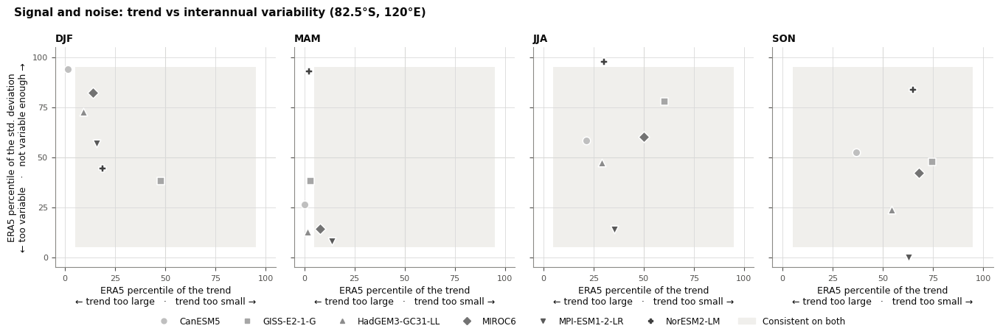

In [96]:
#(t): Signal against noise, every model (its marker and shade of historical's grey), one panel per season: ERA5's
#(t): percentile for the trend (x) and the interannual variability (y); inside the grey square, consistent on both
signal_noise_models = list(eval_table_ds['model'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(SEASONS), n_legends=1, panel_width=2.8,
                                                  panel_height=2.8), layout='constrained')
axes = fig.add_gridspec(1, len(SEASONS)).subplots(sharex=True, sharey=True, squeeze=False)
for ax, season in zip(axes[0], SEASONS):
    evp.plot_signal_noise(eval_table_ds, season, x='trend', y='std', ax=ax)
    ax.set_title(season, loc='left')
    ax.set_xlabel(evp.signal_noise_label('trend'))
axes[0, 0].set_ylabel(evp.signal_noise_label('std'))
fig.legend(handles=charts.model_legend_handles(signal_noise_models, experiment='historical')
           + [Patch(color='#f0efec', label='Consistent on both')],
           loc='outside lower center', ncols=len(signal_noise_models) + 1, frameon=False)
fig.suptitle(f'Signal and noise: trend vs interannual variability ({POINT_LABEL})', x=0.01, ha='left');

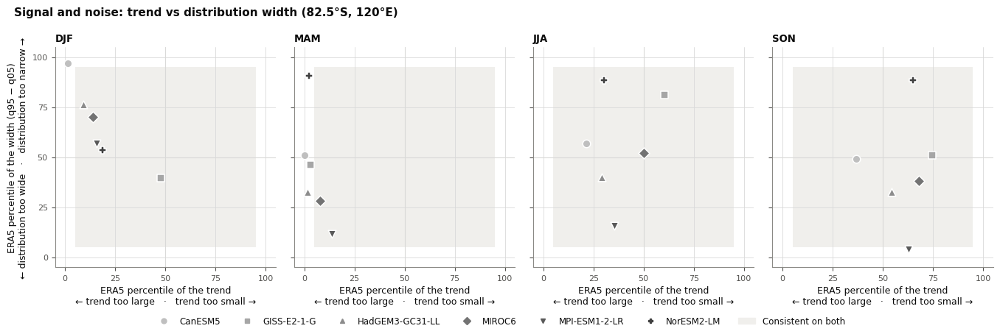

In [97]:
#(t): ... the trend against the distribution's width instead
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(SEASONS), n_legends=1, panel_width=2.8,
                                                  panel_height=2.8), layout='constrained')
axes = fig.add_gridspec(1, len(SEASONS)).subplots(sharex=True, sharey=True, squeeze=False)
for ax, season in zip(axes[0], SEASONS):
    evp.plot_signal_noise(eval_table_ds, season, x='trend', y='width', ax=ax)
    ax.set_title(season, loc='left')
    ax.set_xlabel(evp.signal_noise_label('trend'))
axes[0, 0].set_ylabel(evp.signal_noise_label('width'))
fig.legend(handles=charts.model_legend_handles(signal_noise_models, experiment='historical')
           + [Patch(color='#f0efec', label='Consistent on both')],
           loc='outside lower center', ncols=len(signal_noise_models) + 1, frameon=False)
fig.suptitle(f'Signal and noise: trend vs distribution width ({POINT_LABEL})', x=0.01, ha='left');

## 7. Moment Test Maps

The moment test at every grid point of every model: `ev.locate` on calc_03a's maps, point by point, as at the point. Then the **field test** (`ev.field_test`): a perfect model is flagged at about 10% of grid points by chance, and neighbouring points are correlated, so the question is whether ERA5 is flagged over *more* of the map than a perfect model would be. Each member in turn plays ERA5 against the other N − 1, and the areas they are flagged over show what a perfect model gives (Livezey & Chen, 1983, with the members as the null). It is gone through step by step below, on EXAMPLE_MODEL's standard deviation.

In the maps: ERA5's percentile among each model's members, darkest where it is beyond their 5–95%. Top left of each panel, the field test: the % of the map where ERA5 is flagged, and the most a perfect model gives 90% of the time; ✗ when ERA5 is flagged over more. Models with fewer than 20 members cannot flag anything and are left blank.

In [98]:
#(t): The mean at every grid point: where ERA5's falls among each model's members, point by point (ev.locate)
mean_map_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name], era5_mean_da) for node in historical_mean_tree.leaves
})

In [99]:
#(t): The standard deviation (detrended) at every grid point: where ERA5's falls among each model's members, point by point (ev.locate)
std_map_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name], era5_std_da) for node in historical_std_tree.leaves
})

In [100]:
#(t): The skewness (detrended) at every grid point: where ERA5's falls among each model's members, point by point (ev.locate)
skewness_map_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name], era5_skewness_da) for node in historical_skewness_tree.leaves
})

In [101]:
#(t): The excess kurtosis (detrended) at every grid point: where ERA5's falls among each model's members, point by point (ev.locate)
kurtosis_map_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node[VARIABLE.name], era5_kurtosis_da) for node in historical_kurtosis_tree.leaves
})

In [102]:
#(t): Each model's four along a statistic dim, on (statistic, member, season, lat, lon)
moment_map_test_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), std_map_test_tree[node.path].to_dataset(),
                          skewness_map_test_tree[node.path].to_dataset(), kurtosis_map_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['mean', 'std', 'skewness', 'kurtosis']))
    for node in mean_map_test_tree.leaves
})

**How `ev.field_test` works**, step by step on EXAMPLE_MODEL's map of the standard deviation, in DJF. A perfect model is flagged at about 10% of the grid points by chance, so a map of flags cannot say on its own whether the model fails: the field test asks whether ERA5 is flagged over more of the map than the members are, each member playing ERA5 against the others.

In [103]:
#(t): EXAMPLE_MODEL's standard deviation test at every grid point (std_map_test_tree, above): ERA5's among the members',
#(t): point by point
field_std_ds = std_map_test_tree[EXAMPLE_MODEL]['historical'].to_dataset()

In [104]:
#(t): At each grid point, how many members there are and how many ERA5's is greater than
field_n_da = field_std_ds['members'].notnull().sum('member')
field_less_da = (field_std_ds['members'] < field_std_ds['era5']).sum('member')

In [105]:
#(t): ERA5 tested against N - 1 members, as each pseudo-observation is: the share of the N leave-one-out tests that flag it
# Example: 50 members, and ERA5 greater than 48 of them.
# Leave out one of those 48 (48 of the 50 ways): ERA5 is greater than 47 of the 49 others and 2 are greater than it, so
# p = 2 * (2 + 1) / 50 = 0.12, which is not less than 0.1: not flagged.
# Leave out one of the other 2 (2 of the 50 ways): ERA5 is greater than 48 of the 49 and 1 is greater than it, so
# p = 2 * (1 + 1) / 50 = 0.08: flagged. ERA5 is flagged in 2 of the 50 tests, so this point is given 2 / 50 = 0.04.
# ev._flagged applies ev.locate's p-value rule to a count of the others less than it.
field_era5_flagged_da = ((field_less_da / field_n_da) * ev._flagged(field_less_da - 1, field_n_da - 1, ev.ALPHA)
                         + ((field_n_da - field_less_da) / field_n_da)
                         * ev._flagged(field_less_da, field_n_da - 1, ev.ALPHA))

In [106]:
#(t): Each member as a pseudo-observation: how many of the other N - 1 members it is greater than (ev._rank_among_others),
#(t): and whether that is flagged by the same rule
field_pseudo_less_da = xr.apply_ufunc(ev._rank_among_others, field_std_ds['members'], input_core_dims=[['member']],
                                      output_core_dims=[['member']])
field_pseudo_flagged_da = ev._flagged(field_pseudo_less_da, field_n_da - 1, ev.ALPHA)

In [107]:
#(t): The % of the map flagged (cos-latitude weighted), for ERA5 and for each pseudo-observation
# Only the grid points where a pseudo-observation can be flagged at all count: 2 / N less than 0.1, more than 20 members.
field_present_da = field_std_ds['era5'].notnull() & (2 / field_n_da < ev.ALPHA)
field_weights_da = np.cos(np.deg2rad(field_std_ds['lat']))
field_era5_area_da = 100 * field_era5_flagged_da.astype(float).where(field_present_da).weighted(
    field_weights_da).mean(['lat', 'lon'])
field_pseudo_area_da = 100 * field_pseudo_flagged_da.astype(float).where(field_present_da).weighted(
    field_weights_da).mean(['lat', 'lon'])

In [108]:
#(t): The field p-value: the share of the pseudo-observations flagged over at least as much of the map as ERA5, with ERA5
#(t): counted as one more
# Example: 50 pseudo-observations, 3 of them flagged over at least as much of the map as ERA5: p = (3 + 1) / (50 + 1) = 0.078.
# That is less than 0.1, so ERA5 is flagged over more of the map than a perfect model would be: the model fails.
field_pvalue_da = (((field_pseudo_area_da >= field_era5_area_da).sum('member') + 1)
                   / (field_pseudo_area_da.notnull().sum('member') + 1))

In [109]:
#(t): Check: the steps against ev.field_test (largest difference of the field p-value: 0)
field_check_ds = ev.field_test(field_std_ds)
float(abs(field_pvalue_da - field_check_ds['field_pvalue']).max())

0.0

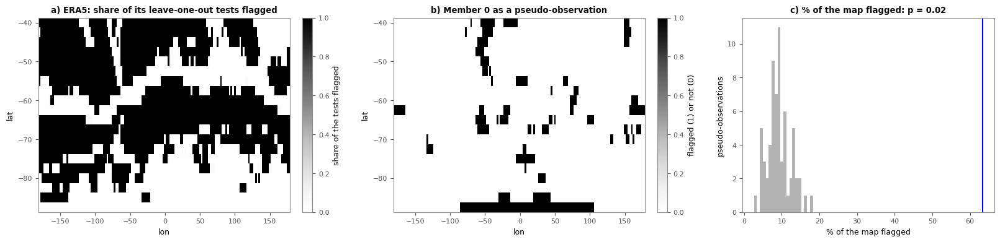

In [110]:
#(t): ev.field_test step by step on EXAMPLE_MODEL's standard deviation in DJF: a) the share of ERA5's leave-one-out tests that
#(t): flag it at each point; b) member 0 as a pseudo-observation, flagged (1) or not (0); c) the % of the map flagged,
#(t): every pseudo-observation (grey) and ERA5 (blue)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), layout='constrained')
field_era5_flagged_da.sel(season='DJF').plot(ax=axes[0], x='lon', y='lat', cmap='Greys', vmin=0, vmax=1,
                                             cbar_kwargs={'label': 'share of the tests flagged'})
axes[0].set_title("a) ERA5: share of its leave-one-out tests flagged")
field_pseudo_flagged_da.isel(member=0).sel(season='DJF').astype(float).plot(ax=axes[1], x='lon', y='lat', cmap='Greys',
                                                                            vmin=0, vmax=1,
                                                                            cbar_kwargs={'label': 'flagged (1) or not (0)'})
axes[1].set_title('b) Member 0 as a pseudo-observation')
field_pseudo_area_da.sel(season='DJF').plot.hist(ax=axes[2], bins=20, color='0.7')
axes[2].axvline(float(field_era5_area_da.sel(season='DJF')), color='blue')
axes[2].set(title=f"c) % of the map flagged: p = {float(field_pvalue_da.sel(season='DJF')):.2f}",
            xlabel='% of the map flagged', ylabel='pseudo-observations');

In [111]:
#(t): The field test of every model, moment and season (ev.field_test), merged with the tests at every grid point, and
#(t): without the members
map_test_tree = xr.DataTree.from_dict({
    node.path: xr.merge([node.to_dataset(), ev.field_test(node.to_dataset())]).drop_dims('member')
    for node in moment_map_test_tree.leaves
})

In [112]:
#(t): Every model in one Dataset, on (model, statistic, season, lat, lon)
eval_map_table_by_experiment_ds = tree_to_dataset(map_test_tree, dims=['model', 'experiment'], coords='minimal',
                                                  compat='override')
eval_map_table_ds = eval_map_table_by_experiment_ds.sel(experiment='historical', drop=True)
eval_map_table_ds

<xarray.Dataset> Size: 18MB
Dimensions:        (model: 6, statistic: 4, lat: 20, lon: 144, season: 4)
Coordinates:
  * model          (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon            (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season         (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat            (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * statistic      (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
Data variables:
    era5           (statistic, lat, lon, season, model) float64 2MB -29.67 .....
    lower          (statistic, lat, lon, season, model) float64 2MB -25.96 .....
    median         (statistic, lat, lon, season, model) float64 2MB -25.62 .....
    upper          (statistic, lat, lon, season, model) float64 2MB -25.33 .....
    percentile     (statistic, lat, lon, season, model) float64 2MB 0.0 ... 3...
    pvalue         (statistic, lat, lon, season, model) float64 2MB 0.0303 .....
    verdict        (statistic, lat, lon, season, model) float64 2MB -1.0 ... 0.0
    testable       (statistic, lat, lon, season, model) float64 2MB 1.0 ... 1.0
    flagged_area   (statistic, season, model) float64 768B 85.54 15.43 ... 7.355
    perfect_area   (statistic, season, model) float64 768B 19.36 20.5 ... 12.14
    field_pvalue   (statistic, season, model) float64 768B 0.01515 ... 0.7955
    field_verdict  (statistic, season, model) float64 768B 1.0 0.0 ... 0.0 0.0

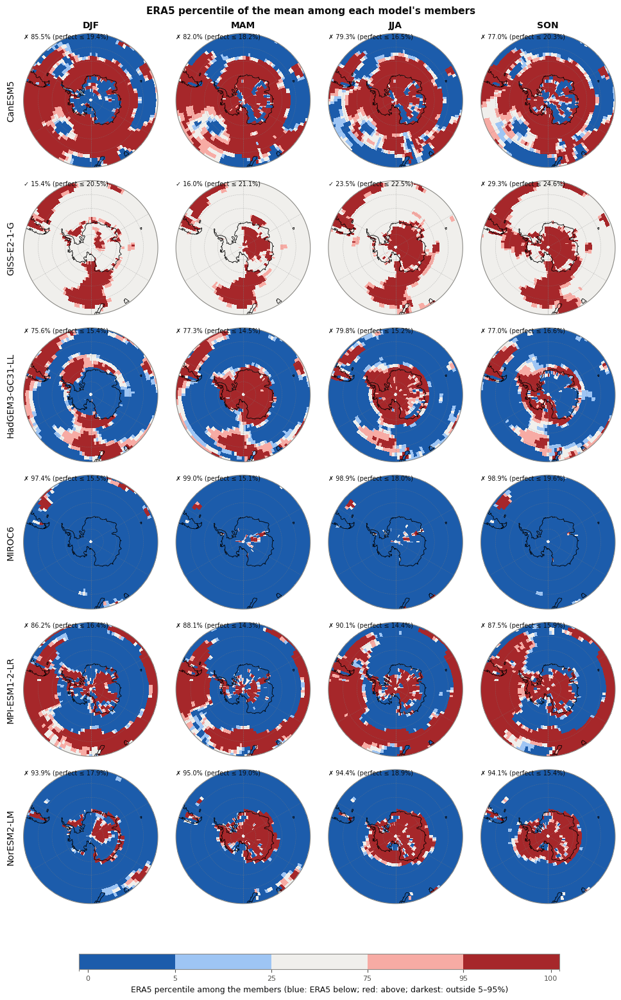

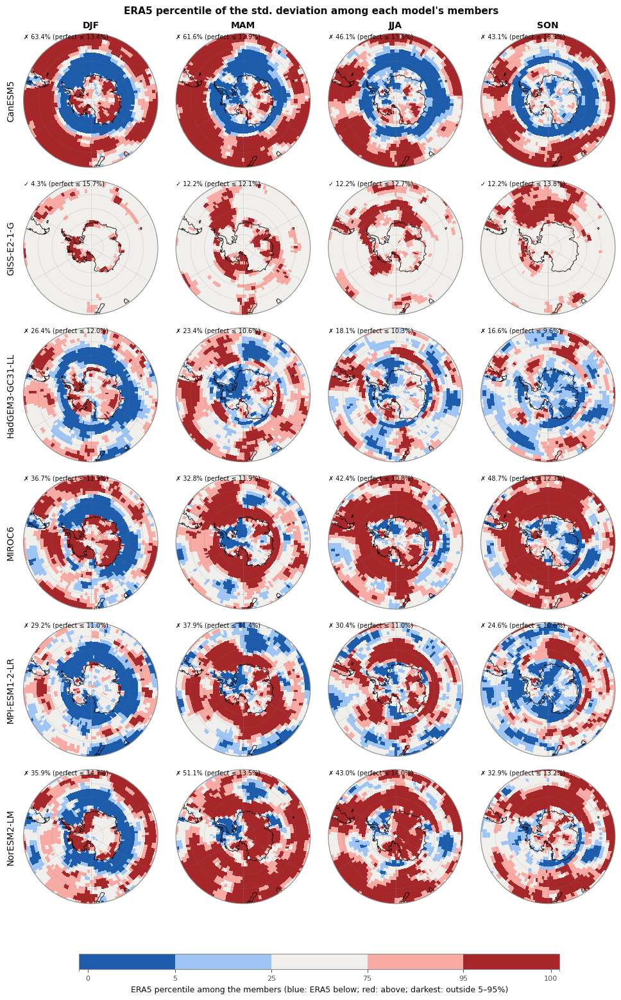

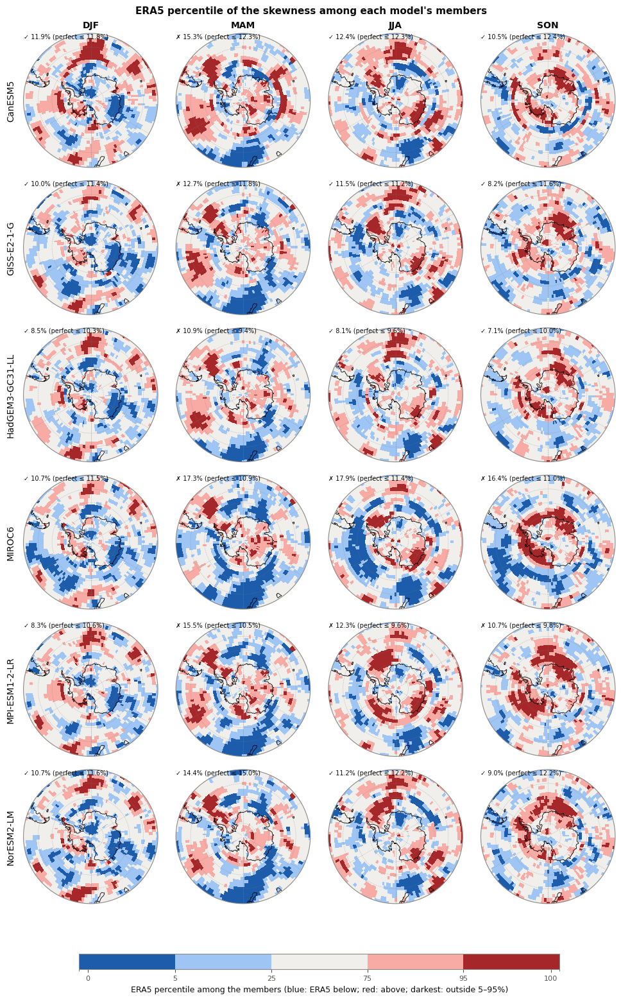

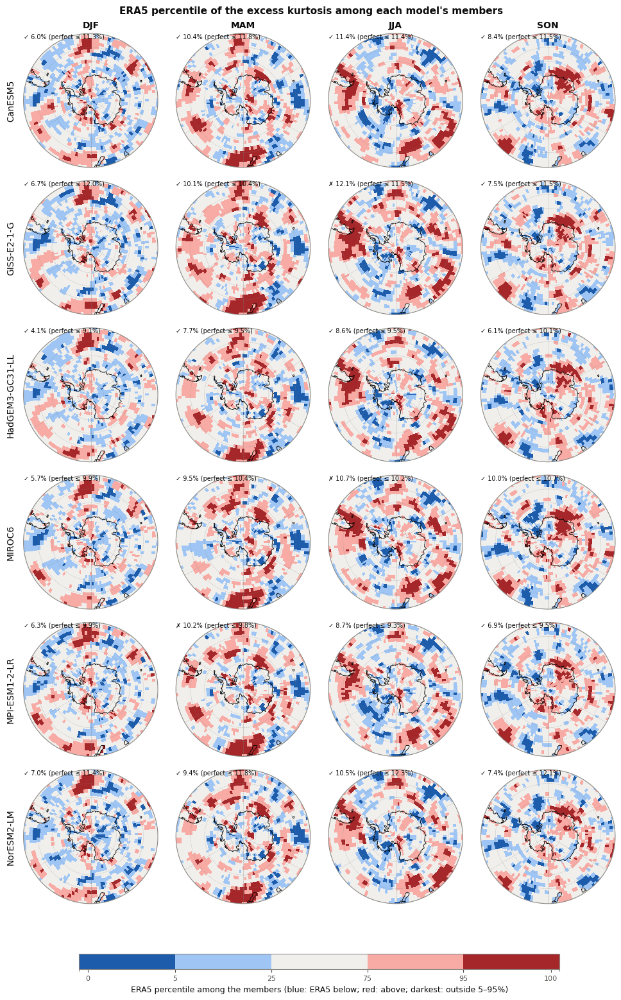

In [113]:
#(t): ERA5's percentile among each model's members (rows), every season, one figure per statistic: blank where a model
#(t): has too few members to test; in each map's corner the field test, ✓ if ERA5 is flagged over no more of the map
#(t): than a perfect model's pseudo-observations would be, ✗ if over more
percentile_cmap, _ = evp.percentile_colormap()
for statistic in ['mean', 'std', 'skewness', 'kurtosis']:
    statistic_ds = eval_map_table_ds.sel(statistic=statistic, season=SEASONS)
    #(c): Blank where too few members can flag anything: a dark class there would mean nothing
    percentile_da = statistic_ds['percentile'].where(statistic_ds['testable'] == 1)
    models = percentile_da['model'].values
    fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1),
                     layout='constrained')
    axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
    cax = antarctica.colorbar_axis_below(axes)

    antarctica.heatmaps_of_antarctica(percentile_da, 'model', 'season', axes=axes, cax=cax,
                                      levels=evp.PERCENTILE_EDGES, cmap=percentile_cmap, extend='neither',
                                      ticks=evp.PERCENTILE_BOUNDS,
                                      label='ERA5 percentile among the members (blue: ERA5 below; red: above; darkest: '
                                            'outside 5–95%)')
    #(c): Each map's note: too few members to test, or the field test's verdict
    for i, model in enumerate(models):
        for j, season in enumerate(SEASONS):
            map_ds = statistic_ds.sel(model=model, season=season)
            if bool(percentile_da.sel(model=model, season=season).isnull().all()):
                axes[i, j].text(0.5, 0.5, 'too few members\nto test (N < 20)', transform=axes[i, j].transAxes,
                                ha='center', va='center', fontsize=8)
            elif 'field_verdict' in map_ds and bool(map_ds['field_verdict'].notnull()):
                mark = '✓' if int(map_ds['field_verdict']) == 0 else '✗'
                axes[i, j].text(0.0, 1.0, f"{mark} {float(map_ds['flagged_area']):.1f}% (perfect ≤ "
                                          f"{float(map_ds['perfect_area']):.1f}%)",
                                transform=axes[i, j].transAxes, ha='left', va='top', fontsize=7)

    antarctica.label_columns(axes, SEASONS)
    antarctica.label_rows(axes, models)
    fig.suptitle(f"ERA5 percentile of the {evp.statistic_label(eval_map_table_ds, statistic).lower()} among each "
                 f"model's members")

TypeError: Plotting requires coordinates to be numeric, boolean, or dates of type numpy.datetime64, datetime.datetime, cftime.datetime or pandas.Interval. Received data of type object instead.

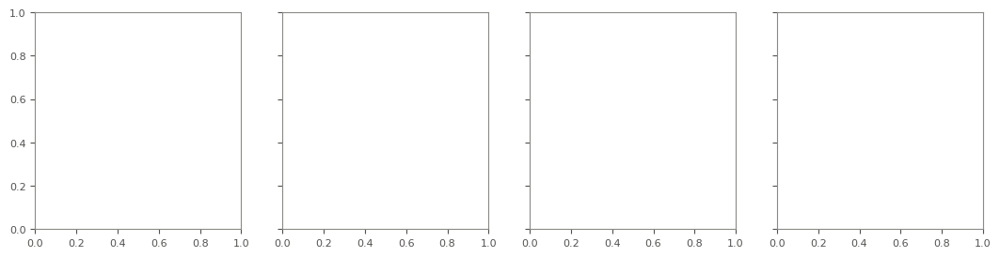

In [114]:
#(t): The field test for every model, moment and season: 1 (✗) where ERA5 is flagged over more of the map than a
#(t): perfect model gives, 0 (✓) where not, blank with too few members
#(c): The model names are Python objects after tree_to_dataset; xarray only puts strings on an axis
field_verdict_da = eval_map_table_ds['field_verdict'].sel(season=SEASONS)
field_verdict_da = field_verdict_da.assign_coords(model=field_verdict_da['model'].astype(str))
fg = field_verdict_da.plot(x='season', y='model', col='statistic', vmin=0, vmax=1, cmap='Reds', add_colorbar=False)

In [ ]:
#(t): How many models are consistent with ERA5 (ERA5 inside their members' 5-95%) at each grid point
#(c): Only models with enough members to be tested (N >= 20) are counted, as consistent or not
testable_da = eval_map_table_ds['testable'] == 1
n_eval_models = int(testable_da.any([dim for dim in testable_da.dims if dim != 'model']).sum())
count_cmap, _ = rcp.count_colormap(n_eval_models, base_cmap='Blues')
n_consistent_da = ((eval_map_table_ds['verdict'] == 0) & testable_da).sum('model')
statistics = n_consistent_da['statistic'].values

#(c): Every statistic (rows) and season, one colour bar: white for none, a darker blue for each model more
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(statistics), n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(statistics), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)
antarctica.heatmaps_of_antarctica(n_consistent_da.sel(season=SEASONS), 'statistic', 'season', axes=axes,
                                  cax=cax, levels=np.arange(-0.5, n_eval_models + 1.5), cmap=count_cmap,
                                  extend='neither', ticks=range(n_eval_models + 1),
                                  label="Models with ERA5 inside their members' 5-95% range")
antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, [ev.MOMENTS[statistic].label for statistic in statistics])
fig.suptitle('Number of models consistent with ERA5');

## 8. Spatial Evaluation (Suarez-Gutierrez et al., 2021)

The paper's grid-point evaluation (their sections 2.2.2 and 3.2–3.4), at every grid point and season. It does not use the members-as-observations rank histograms of section 5 (the paper keeps those for the global mean). Instead it reduces each point's rank histogram to three numbers and compares them with what a perfect model gives, using fixed thresholds (`ev.spatial_evaluation`):

1. **Anomalies.** Every member and ERA5 minus its own mean over 1979–2013, so a constant offset is gone and the forced change and the variability are left. (The paper uses 1961–1990, which is before ERA5 starts.)
2. **Years.** Only years ERA5 has; a point with fewer than 10 is not tested.
3. **Rank.** Each year, is ERA5 below every member (rank 0), above every member (rank N), or in between?
4. **Three percentages.** The % of years below every member, above every member, and inside the members' central 75% (12.5–87.5%).
5. **Against a perfect model.** If ERA5 were one more member, it would be below every member in 100 / (N + 1) % of years (2% for 50 members), above in as many, and in the central 75% about 75% of the time. Short records push these up by chance, so the paper flags only **≥ 10% below**, **≥ 10% above** or **> 80% in the middle**. Models with N < 20 are not tested with these thresholds: 10 members already put ERA5 beyond them 9% of the time on each side. `SPATIAL_THRESHOLDS = 'perfect_model'` (not in the paper) sets the thresholds from the members instead: each member in turn is treated as ERA5 against the other N − 1, and a percentage counts as a problem above the 95th percentile of theirs. That works for any N.
6. **Diagnosis**, using when the edge years fall (1979–1996 or 1997–2013):

| ERA5 is … | Diagnosis |
|---|---|
| below the members mostly late, or above them mostly early | the model **warms too much** (forced response too strong) |
| above the members mostly late, or below them mostly early | the model **warms too little** |
| both below and above, throughout | **too little variability**: the spread is too narrow |
| in the central 75% more than 80% of the time | **too much variability**: the spread is too wide |
| beyond one edge only, throughout | **one tail too short**: the shape of the distribution |
| none of these | **adequate** |

   The sign flips with time because anomalies are taken over the whole record: a model that warms too fast looks too cold early and too warm late, relative to ERA5. With both edges beyond 10%, both must point the same way to count as the forced response.
7. **Early against late.** A model's variability changes little over time, but the forcing does. So each problem over the whole record is checked for an uneven split between 1979–1996 and 1997–2013 (a binomial test, p < 0.1). Spread evenly, it is the **variability**; concentrated in one period, or flipping between them, the **forced response**. Each half is only ~17 years per season, too short to compare its own flags directly, which in 17 years would flag even a perfect model's middle about a third of the time.
8. **Score.** The adequate share of the tested area per model (each panel's corner), and how many models are adequate at each grid point (the paper's Fig. 8).

In [ ]:
#(t): The spatial evaluation in the order of the seasons, and its models: the rows of the maps below
spatial_seasons_ds = spatial_table_ds.sel(season=SEASONS)
models = spatial_seasons_ds['model'].values

In [ ]:
#(t): The paper's Fig. 5: ERA5 above (red) or below (blue) every member in at least 10% (light) or 20% (dark) of years,
#(t): purple both; hatched where ERA5 is in the members' central 75% too often (> ev.CENTRAL_THRESHOLD = 80% of years
#(t): ////, > 90% xxxx). The classes' names on two lines ('above\n≥ 10%'), so they fit under the bar
edge_names = [name.replace(' ≥', '\n≥') for name in evp.EDGE_CLASSES]
#(c): The classes' colour bar under the maps, then the hatching's legend
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1,
                                                    n_legends=1, colorbar_height=1.0), layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(evp.edge_class(spatial_seasons_ds), 'model', 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, len(edge_names)), cmap=ListedColormap(evp.EDGE_COLORS),
                                  extend='neither', ticks=range(len(edge_names)), ticklabels=edge_names,
                                  label='% of years ERA5 is above (red) or below (blue) every member')
antarctica.hatching_grid(spatial_seasons_ds['central'] > ev.CENTRAL_THRESHOLD, 'model', 'season', axes=axes,
                         pattern='////')
antarctica.hatching_grid(spatial_seasons_ds['central'] > 90, 'model', 'season', axes=axes, pattern='xxxx')
#(c): Each map's note: not tested, or the share of the map where the model is adequate
for i, model in enumerate(models):
    for j, season in enumerate(SEASONS):
        map_ds = spatial_seasons_ds.sel(model=model, season=season)
        if bool(map_ds['adequate'].isnull().all()):
            axes[i, j].text(0.5, 0.5, f'not tested\n(N < {ev.MIN_MEMBERS} or < {ev.MIN_YEARS} years)',
                            transform=axes[i, j].transAxes, ha='center', va='center', fontsize=8)
        else:
            axes[i, j].text(0.0, 1.0, f'adequate {float(ev.adequate_area(map_ds)):.0f}%', transform=axes[i, j].transAxes,
                            ha='left', va='top', fontsize=7.5)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
#(c): The hatching's legend, under the colour bar
fig.legend(handles=[Patch(facecolor='white', edgecolor='0.35', hatch='////',
                          label=f"ERA5 in the members' central 75% in > {ev.CENTRAL_THRESHOLD}% of years"),
                    Patch(facecolor='white', edgecolor='0.35', hatch='xxxx', label='... in > 90% of years')],
           loc='outside lower center', ncols=2, frameon=False, fontsize=9)
fig.suptitle('Where ERA5 is beyond the ensemble, or too often in its middle');

In [ ]:
#(t): What is wrong at each grid point (step 6)
#(c): The classes' names on lines of up to 12 characters, so they fit under the bar, which gets the room for them
class_names = [textwrap.fill(name, 12) for name in ev.DIAGNOSES.values()]
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1,
                                                    colorbar_height=1.0), layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(spatial_seasons_ds['diagnosis'], 'model', 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, len(class_names)), cmap=ListedColormap(evp.DIAGNOSIS_COLORS),
                                  extend='neither', ticks=range(len(class_names)), ticklabels=class_names)
#(c): Each map's note: not tested, or the share of the map where the model is adequate
for i, model in enumerate(models):
    for j, season in enumerate(SEASONS):
        map_ds = spatial_seasons_ds.sel(model=model, season=season)
        if bool(map_ds['adequate'].isnull().all()):
            axes[i, j].text(0.5, 0.5, f'not tested\n(N < {ev.MIN_MEMBERS} or < {ev.MIN_YEARS} years)',
                            transform=axes[i, j].transAxes, ha='center', va='center', fontsize=8)
        else:
            axes[i, j].text(0.0, 1.0, f'adequate {float(ev.adequate_area(map_ds)):.0f}%', transform=axes[i, j].transAxes,
                            ha='left', va='top', fontsize=7.5)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
fig.suptitle('What is wrong at each grid point');

In [ ]:
#(t): Each problem early vs late: the same (variability) or changing (forced response)?
#(c): The classes' names on lines of up to 20 characters, so they fit under the bar, which gets the room for them
class_names = [textwrap.fill(name, 20) for name in ev.PERIOD_DIAGNOSES.values()]
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1,
                                                    colorbar_height=1.0), layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(spatial_seasons_ds['period_diagnosis'], 'model', 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, len(class_names)), cmap=ListedColormap(evp.PERIOD_COLORS),
                                  extend='neither', ticks=range(len(class_names)), ticklabels=class_names)
#(c): Each map's note: not tested, or the share of the map where the model is adequate
for i, model in enumerate(models):
    for j, season in enumerate(SEASONS):
        map_ds = spatial_seasons_ds.sel(model=model, season=season)
        if bool(map_ds['adequate'].isnull().all()):
            axes[i, j].text(0.5, 0.5, f'not tested\n(N < {ev.MIN_MEMBERS} or < {ev.MIN_YEARS} years)',
                            transform=axes[i, j].transAxes, ha='center', va='center', fontsize=8)
        else:
            axes[i, j].text(0.0, 1.0, f'adequate {float(ev.adequate_area(map_ds)):.0f}%', transform=axes[i, j].transAxes,
                            ha='left', va='top', fontsize=7.5)

antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
fig.suptitle('Each problem early vs late: the same (variability) or changing (forced response)?');

In [ ]:
#(t): The score: % of the tested area where each model is adequate, per season
ev.adequate_area(spatial_table_ds).sel(season=SEASONS).to_pandas().plot.bar(rot=0, ylabel='% of the area adequate');

In [ ]:
#(t): The paper's Fig. 8: how many models are adequate at each grid point, every season (white for none)
adequate_count_ds = ev.adequate_count(spatial_table_ds).sel(season=SEASONS)
n_tested = int(adequate_count_ds['n_tested'].max())
adequate_cmap = ListedColormap(['#ffffff', *plt.get_cmap('Blues')(np.linspace(0.3, 1, max(n_tested, 1)))])
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=1, n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=1, n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(adequate_count_ds['n_adequate'].where(adequate_count_ds['n_tested'] > 0), None, 'season',
                                  axes=axes, cax=cax, levels=np.arange(-0.5, n_tested + 1), cmap=adequate_cmap,
                                  extend='neither', ticks=range(n_tested + 1),
                                  label=f'Models with no problem (of the {n_tested} tested)')
antarctica.label_columns(axes, SEASONS)
fig.suptitle('Number of models that adequately capture ERA5');

**Reading these maps**
- A model warming too much shows blue (ERA5 below every member) in the late period and red early, and a forced-response verdict for the period split. Too little variability shows as purple (both edges) with a variability verdict.
- Hatching (too much variability) is the least robust signal with ~35 years per season: the paper notes that short periods put the observations in the middle of the ensemble too often by chance.
- Each grid point is tested on ~35 values, so expect some flags by chance; read coherent regions. A regional mean (as in the observed-change section) is the more robust check, as the paper recommends.

# Part 2: Observed Change

## 1. Consistency with Each Experiment

Each row is one experiment: its members' 1979–2013 trends (dots) and their 5–95% range (bar); the black line is ERA5's. Where the line crosses a row's bar (✓), that experiment could have produced the observed trend. ERA5 outside **hist-nat** is a detection of forced change; ERA5 inside **historical** is consistency.

In [ ]:
#(t): EXAMPLE_MODEL's experiments, each a dict entry of its ev.locate results on (statistic, season)
obs_model_results = {node.name: node.to_dataset() for node in region_tests_tree[EXAMPLE_MODEL].leaves if node.data_vars}

In [ ]:
#(t): The observed trend against each experiment's members' trends, one panel per season: ✓ where ERA5 is inside the
#(t): members' 5-95%
#(c): Gaps between the panels wide enough for each row's verdict, right of it
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(SEASONS), n_legends=2, panel_width=2.6,
                                                  left_margin=1.0, column_gap=1.5), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(1, len(SEASONS)).subplots(sharey=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for ax, season in zip(axes[0], SEASONS):
    ocp.plot_experiment_strips({experiment: results_ds.sel(season=season)
                                for experiment, results_ds in obs_model_results.items()}, 'trend', ax=ax)
    ax.set_title(season, loc='left')
    ax.set_xlabel(f"{ev.DIAGNOSTICS['trend'].label} ({ev.DIAGNOSTICS['trend'].units})")
strip_handles = ocp.experiment_strip_legend_handles()
legend_axes[0].legend(handles=strip_handles[:3], loc='center', ncols=3, frameon=False)
legend_axes[1].legend(handles=strip_handles[3:], loc='center', ncols=3, frameon=False)
fig.suptitle(f'Observed trend vs each experiment: {EXAMPLE_MODEL}, {OBS_REGION}', x=0.01, ha='left');

In [ ]:
#(t): The same for the S/N against itself (smoothed change over the record / its own noise)
#(c): Gaps between the panels wide enough for each row's verdict, right of it
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(SEASONS), n_legends=2, panel_width=2.6,
                                                  left_margin=1.0, column_gap=1.5), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(1, len(SEASONS)).subplots(sharey=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for ax, season in zip(axes[0], SEASONS):
    ocp.plot_experiment_strips({experiment: results_ds.sel(season=season)
                                for experiment, results_ds in obs_model_results.items()}, 'emergence', ax=ax)
    ax.set_title(season, loc='left')
    ax.set_xlabel(ev.DIAGNOSTICS['emergence'].label)
legend_axes[0].legend(handles=strip_handles[:3], loc='center', ncols=3, frameon=False)
legend_axes[1].legend(handles=strip_handles[3:], loc='center', ncols=3, frameon=False)
fig.suptitle(f'Observed S/N vs each experiment: {EXAMPLE_MODEL}, {OBS_REGION}', x=0.01, ha='left');

In [ ]:
#(t): Every model's trend verdicts only (no members), the experiments as the scorecard's columns
trend_verdicts_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset()[['percentile', 'verdict', 'testable']].sel(statistic='trend', drop=True)
    for node in region_tests_tree.leaves
})
trend_table_ds = tree_to_dataset(trend_verdicts_tree, dims=['model', 'experiment'])
trend_table_ds = trend_table_ds.rename(experiment='statistic')
trend_table_ds

In [ ]:
#(t): ERA5's 1979-2013 trend among each experiment's members: every model (rows), experiment and season (columns)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.44 * trend_table_ds.sizes['statistic'] * len(SEASONS),
                                                  panel_height=0.46 * trend_table_ds.sizes['model'], left_margin=1.5),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
trend_scorecard_image = evp.plot_scorecard(trend_table_ds, ax=axes[0, 0])
fig.colorbar(trend_scorecard_image, ax=axes, location='bottom', shrink=0.6, ticks=evp.PERCENTILE_BOUNDS,
             label='ERA5 percentile among the members')
fig.suptitle(f"ERA5's 1979-2013 trend among each experiment's members ({OBS_REGION})", x=0.01, ha='left');

## 2. Record Rates

Cumulative record highs and lows through 1979–2013, with the four seasons pooled so there are enough records to compare. The dashed curve is what a climate with no change gives (1 + 1/2 + … + 1/*n* per season). Record highs arriving faster than that, and faster than the hist-nat members', mean warming the natural range cannot produce; record lows arriving slower mean the cold end has moved too.

In [ ]:
#(t): Cumulative record highs and lows in OBS_REGION, all seasons pooled: ERA5 against chance (dashed) and against
#(t): hist-nat's and historical's members (median and 5-95%)
record_kinds = list(record_curves_ds['kind'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(record_kinds), n_legends=1, panel_width=4.5,
                                                  panel_height=3.0), layout='constrained')
axes = fig.add_gridspec(1, len(record_kinds)).subplots(squeeze=False)
for ax, kind in zip(axes[0], record_kinds):
    ocp.plot_record_rates(record_curves_ds, kind, ax=ax)
    ax.set_title(f'Record {kind}', loc='left')
    ax.set_xlabel('Year')
axes[0, 0].set_ylabel('Cumulative number of records')
fig.legend(handles=ocp.record_rate_legend_handles(), loc='outside lower center', ncols=4, frameon=False)
fig.suptitle(f'Record rates, all seasons pooled: {EXAMPLE_MODEL}, {OBS_REGION}', x=0.01, ha='left');

In [ ]:
#(t): At the point (much noisier than a regional mean)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(record_kinds), n_legends=1, panel_width=4.5,
                                                  panel_height=3.0), layout='constrained')
axes = fig.add_gridspec(1, len(record_kinds)).subplots(squeeze=False)
for ax, kind in zip(axes[0], record_kinds):
    ocp.plot_record_rates(point_curves_ds, kind, ax=ax)
    ax.set_title(f'Record {kind}', loc='left')
    ax.set_xlabel('Year')
axes[0, 0].set_ylabel('Cumulative number of records')
fig.legend(handles=ocp.record_rate_legend_handles(), loc='outside lower center', ncols=4, frameon=False)
fig.suptitle(f'Record rates, all seasons pooled: {EXAMPLE_MODEL}, {POINT_LABEL}', x=0.01, ha='left');

## 3. Detection Maps

The trend test at every grid point: detected (outside hist-nat's 5–95%) and consistent (inside historical's). At p < 0.1 about 10% of points land outside a range by chance; read coherent regions.

In [ ]:
#(t): Is the observed (ERA5) trend detectable, and is historical consistent with it: every model (rows) and season, the
#(t): detection classes (oc.DETECTION_CLASSES); a map with no class at all is an ensemble too small to test
detection_class_da = detections_ds['detection_class'].sel(season=SEASONS)
models = detection_class_da['model'].values
class_names = [name.replace(', ', ',\n') for name in oc.DETECTION_CLASSES.values()]
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(detection_class_da, 'model', 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, len(ocp.DETECTION_COLORS)), cmap=ListedColormap(ocp.DETECTION_COLORS),
                                  extend='neither', ticks=range(len(ocp.DETECTION_COLORS)), ticklabels=class_names,
                                  label="Detected: outside hist-nat's 5–95%. Consistent: inside historical's 5–95%.")
#(c): Say so where a map has no class at all, rather than leave it blank
for i, model in enumerate(models):
    for j, season in enumerate(SEASONS):
        if bool(detection_class_da.sel(model=model, season=season).isnull().all()):
            axes[i, j].text(0.5, 0.5, 'too few members\nto test (N < 20)', transform=axes[i, j].transAxes,
                            ha='center', va='center', fontsize=9)
antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
fig.suptitle('Is the observed (ERA5) trend detectable, and is historical consistent with it?');

In [ ]:
#(t): How many models call each point detected and consistent (class 1), every season (white for none)
n_detection_models = detections_ds.sizes['model']
detection_counts_da = (detections_ds['detection_class'] == 1).sum('model').sel(season=SEASONS)
detection_count_cmap, _ = rcp.count_colormap(n_detection_models, 'Blues')
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=1, n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=1, n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(detection_counts_da, None, 'season', axes=axes, cax=cax,
                                  levels=np.arange(-0.5, n_detection_models + 1.5), cmap=detection_count_cmap,
                                  extend='neither', ticks=range(n_detection_models + 1), label='Number of models')
antarctica.label_columns(axes, SEASONS)
fig.suptitle(f'Number of models where the observed trend is {oc.DETECTION_CLASSES[1]}');

## 4. Scaling Factors: How Much of Each Response Is Observed

β = 1 (the dashed line): the model's response has the observed size; an interval clear of 0 is a detection. The grey tick is the perfect-model median, which shows any bias in the method; it should be close to 1.

In [ ]:
#(t): Two signals, anthropogenic (ANT) and natural (NAT): their scaling factors in each region (panels), every model
#(t): (marker) and signal (colour); β = 1 dashed, β = 0 grey
scaling_regions = list(scaling_ant_nat_ds['region'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(scaling_regions), n_legends=1),
                 layout='constrained')
axes = fig.add_gridspec(1, len(scaling_regions)).subplots(sharey=True, squeeze=False)
for ax, region in zip(axes[0], scaling_regions):
    ocp.plot_scaling_factors(scaling_ant_nat_ds.sel(region=region), ax=ax)
    ax.set_title(region, loc='left')
axes[0, 0].set_ylabel('Scaling factor β')
scaling_handles = ocp.scaling_factor_legend_handles(scaling_ant_nat_ds['model'].values)
fig.legend(handles=scaling_handles, loc='outside lower center', ncols=len(scaling_handles), frameon=False)
fig.suptitle('Scaling factors: anthropogenic (ANT) and natural (NAT)', x=0.01, ha='left');

In [ ]:
#(t): ... and how much of the observed trend each explains (β × the signal's trend), every model (rows)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(scaling_regions), n_legends=1,
                                                  panel_width=3.6, left_margin=1.5), layout='constrained')
axes = fig.add_gridspec(1, len(scaling_regions)).subplots(sharey=True, squeeze=False)
for ax, region in zip(axes[0], scaling_regions):
    ocp.plot_attributable_trends(scaling_ant_nat_ds.sel(region=region), ax=ax)
    ax.set_title(region, loc='left')
    ax.set_xlabel('Trend 1979–2014 (°C/decade)')
attributable_handles = ocp.attributable_trend_legend_handles(scaling_ant_nat_ds['signal'].values)
fig.legend(handles=attributable_handles, loc='outside lower center', ncols=len(attributable_handles), frameon=False)
fig.suptitle('How much of the observed trend ANT and NAT explain', x=0.01, ha='left');

In [ ]:
#(t): Four signals, greenhouse gases, aerosols, ozone and natural: their scaling factors
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(scaling_regions), n_legends=1),
                 layout='constrained')
axes = fig.add_gridspec(1, len(scaling_regions)).subplots(sharey=True, squeeze=False)
for ax, region in zip(axes[0], scaling_regions):
    ocp.plot_scaling_factors(scaling_single_ds.sel(region=region), ax=ax)
    ax.set_title(region, loc='left')
axes[0, 0].set_ylabel('Scaling factor β')
scaling_handles = ocp.scaling_factor_legend_handles(scaling_single_ds['model'].values)
fig.legend(handles=scaling_handles, loc='outside lower center', ncols=len(scaling_handles), frameon=False)
fig.suptitle('Scaling factors: single forcings', x=0.01, ha='left');

In [ ]:
#(t): ... and how much of the observed trend each explains
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=len(scaling_regions), n_legends=1,
                                                  panel_width=3.6, left_margin=1.5), layout='constrained')
axes = fig.add_gridspec(1, len(scaling_regions)).subplots(sharey=True, squeeze=False)
for ax, region in zip(axes[0], scaling_regions):
    ocp.plot_attributable_trends(scaling_single_ds.sel(region=region), ax=ax)
    ax.set_title(region, loc='left')
    ax.set_xlabel('Trend 1979–2014 (°C/decade)')
attributable_handles = ocp.attributable_trend_legend_handles(scaling_single_ds['signal'].values)
fig.legend(handles=attributable_handles, loc='outside lower center', ncols=len(attributable_handles), frameon=False)
fig.suptitle('How much of the observed trend each forcing explains', x=0.01, ha='left');